# Classical Computer Vision Pipeline for Imagenette Classification
**Course:** Machine Vision (Fall 2026) — Amirkabir University of Technology (Tehran Polytechnic)  
**Instructor:** Dr. Shariatmadar Mortazavi  
**Student:** Kasra Adimi (`40123006`)

---

## Project Overview
This notebook implements an end-to-end **classical computer vision** classification pipeline on the 10-class **Imagenette2** dataset without using any deep neural networks (CNNs, Transformers, etc.). The workflow covers:
1. Reproducible environment setup and hardware benchmarking.
2. Strict train/validation isolation and exploratory data analysis (EDA).
3. Multi-modal classical feature extraction (Color, Shape/Edge, Texture, Frequency, and Local Keypoints via BoVW/VLAD).
4. Feature fusion, normalization, and a systematic Ablation Study.
5. Classical ML classifier optimization, ensembling, and targeted off-diagonal error analysis.

## 1. Environment Setup, Reproducibility & Hardware Logging
In this section, we import the required libraries, configure project directories (`dataset` and `cache`), and lock the global random seed (`SEED = 42`) across Python and NumPy to guarantee reproducible results. We also log the system's hardware specifications (OS, CPU cores, and RAM) for runtime benchmarking in the final report.

In [1]:
import os
import random
import platform
import time
from pathlib import Path

import cv2
import psutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm

# 1. Reproducibility (Global Random Seed)
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
os.environ["PYTHONHASHSEED"] = str(SEED)

# 2. Project Paths
BASE_DIR = Path(".")
DATASET_DIR = BASE_DIR / "dataset" / "imagenette2"
CACHE_DIR = BASE_DIR / "cache"
CACHE_DIR.mkdir(parents=True, exist_ok=True)

# 3. Log Hardware & Environment Specs (Required for Report)
print("=== Hardware & Environment Specifications ===")
print(f"OS: {platform.system()} {platform.release()}")
print(f"Python: {platform.python_version()}")
print(f"CPU: {platform.processor() or platform.machine()} | Physical cores: {psutil.cpu_count(logical=False)}, Logical cores: {psutil.cpu_count(logical=True)}")
print(f"RAM: {psutil.virtual_memory().total / (1024**3):.2f} GB")

=== Hardware & Environment Specifications ===
OS: Linux 7.0.0-43-generic
Python: 3.12.3
CPU: x86_64 | Physical cores: 4, Logical cores: 8
RAM: 15.32 GB


## 2. Dataset Loading & Strict Train/Validation Isolation
Here, we map the 10 ImageNet WordNet IDs (`wnid`) to their corresponding human-readable class labels and build structured DataFrames for the default `train` and `val` splits.

> **Data Leakage Prevention Policy:** The `val` split is strictly quarantined and reserved exclusively for final model evaluation. All exploratory analysis, feature scaling, visual vocabulary clustering (K-Means), and hyperparameter tuning will be performed solely on the `train` split.

In [2]:
# Mapping WordNet IDs to human-readable class names
CLASS_MAP = {
    "n01440764": "Tench",
    "n02102040": "English Springer",
    "n02979186": "Cassette Player",
    "n03000684": "Chain Saw",
    "n03028079": "Church",
    "n03394916": "French Horn",
    "n03417042": "Garbage Truck",
    "n03425413": "Gas Pump",
    "n03445777": "Golf Ball",
    "n03888257": "Parachute",
}

# Sorted label encoding (0 to 9) for consistency
WNID_TO_IDX = {wnid: idx for idx, wnid in enumerate(sorted(CLASS_MAP.keys()))}
IDX_TO_NAME = {idx: CLASS_MAP[wnid] for wnid, idx in WNID_TO_IDX.items()}

def build_split_df(split_dir: Path) -> pd.DataFrame:
    records = []
    for wnid, label_idx in WNID_TO_IDX.items():
        class_dir = split_dir / wnid
        if not class_dir.exists():
            raise FileNotFoundError(f"Missing directory: {class_dir}")
        for img_path in sorted(class_dir.glob("*")):
            if img_path.suffix.lower() in {".jpeg", ".jpg", ".png"}:
                records.append({
                    "path": str(img_path),
                    "wnid": wnid,
                    "label": label_idx,
                    "class_name": CLASS_MAP[wnid]
                })
    return pd.DataFrame(records)

train_df = build_split_df(DATASET_DIR / "train")
val_df = build_split_df(DATASET_DIR / "val")

print(f"Train samples: {len(train_df)}")
print(f"Val samples:   {len(val_df)}")
train_df.head()

Train samples: 9469
Val samples:   3925


,path,wnid,label,class_name
0,dataset/imagenette2/train/n01440764/ILSVRC2012...,n01440764,0,Tench
1,dataset/imagenette2/train/n01440764/ILSVRC2012...,n01440764,0,Tench
2,dataset/imagenette2/train/n01440764/ILSVRC2012...,n01440764,0,Tench
3,dataset/imagenette2/train/n01440764/ILSVRC2012...,n01440764,0,Tench
4,dataset/imagenette2/train/n01440764/ILSVRC2012...,n01440764,0,Tench


## 3. Exploratory Data Analysis (EDA)
Before designing the preprocessing and feature extraction pipeline, we inspect the `train` split to identify potential edge cases and guide our architectural choices:
- **Class Balance:** Verify sample counts across all 10 classes in both splits.
- **Channel Consistency:** Detect grayscale (1-channel) or RGBA (4-channel) images that must be standardized to 3-channel RGB before extracting color descriptors.
- **Resolution & Aspect Ratio Distribution:** Analyze image dimensions to select appropriate resizing strategies for global descriptors (e.g., HOG) versus local keypoint detectors (e.g., SIFT/ORB).

In [3]:
# 1. Class distribution comparison
dist_df = pd.DataFrame({
    "Train": train_df["class_name"].value_counts(),
    "Val": val_df["class_name"].value_counts()
})
display(dist_df)

# 2. Inspect image shapes, channels, and aspect ratios on Train split
heights, widths, channels = [], [], []
corrupted_files = []

for path in tqdm(train_df["path"], desc="Inspecting Train Images"):
    img = cv2.imread(path, cv2.IMREAD_UNCHANGED)
    if img is None:
        corrupted_files.append(path)
        continue
    if img.ndim == 2:
        h, w = img.shape
        c = 1
    else:
        h, w, c = img.shape
    heights.append(h)
    widths.append(w)
    channels.append(c)

eda_stats = pd.DataFrame({
    "height": heights,
    "width": widths,
    "channels": channels,
    "aspect_ratio": np.array(widths) / np.array(heights)
})

print(f"\nCorrupted images: {len(corrupted_files)}")
print("Channel distribution:\n", eda_stats["channels"].value_counts())
print("\nResolution & Aspect Ratio Summary:")
display(eda_stats[["width", "height", "aspect_ratio"]].describe().round(2))

,Train,Val
class_name,,
Cassette Player,993,357
Chain Saw,858,386
Church,941,409
English Springer,955,395
French Horn,956,394
Garbage Truck,961,389
Gas Pump,931,419
Golf Ball,951,399
Parachute,960,390


Inspecting Train Images:   0%|          | 0/9469 [00:00<?, ?it/s]


Corrupted images: 0
Channel distribution:
 channels
3    9296
1     173
Name: count, dtype: int64

Resolution & Aspect Ratio Summary:


,width,height,aspect_ratio
count,9469.00,9469.00,9469.00
mean,471.60,407.77,1.22
std,228.98,201.61,0.35
min,50.00,27.00,0.23
25%,375.00,333.00,0.95
50%,500.00,375.00,1.33
75%,500.00,500.00,1.40
max,4288.00,4368.00,5.02


## 4. Visual Inspection of Class Samples
To build domain intuition for classical feature engineering, we visualize one representative image from each of the 10 classes along with its native resolution. Observing dominant colors, geometric structures, surface textures, and background clutter helps prioritize which feature families will be most discriminative.

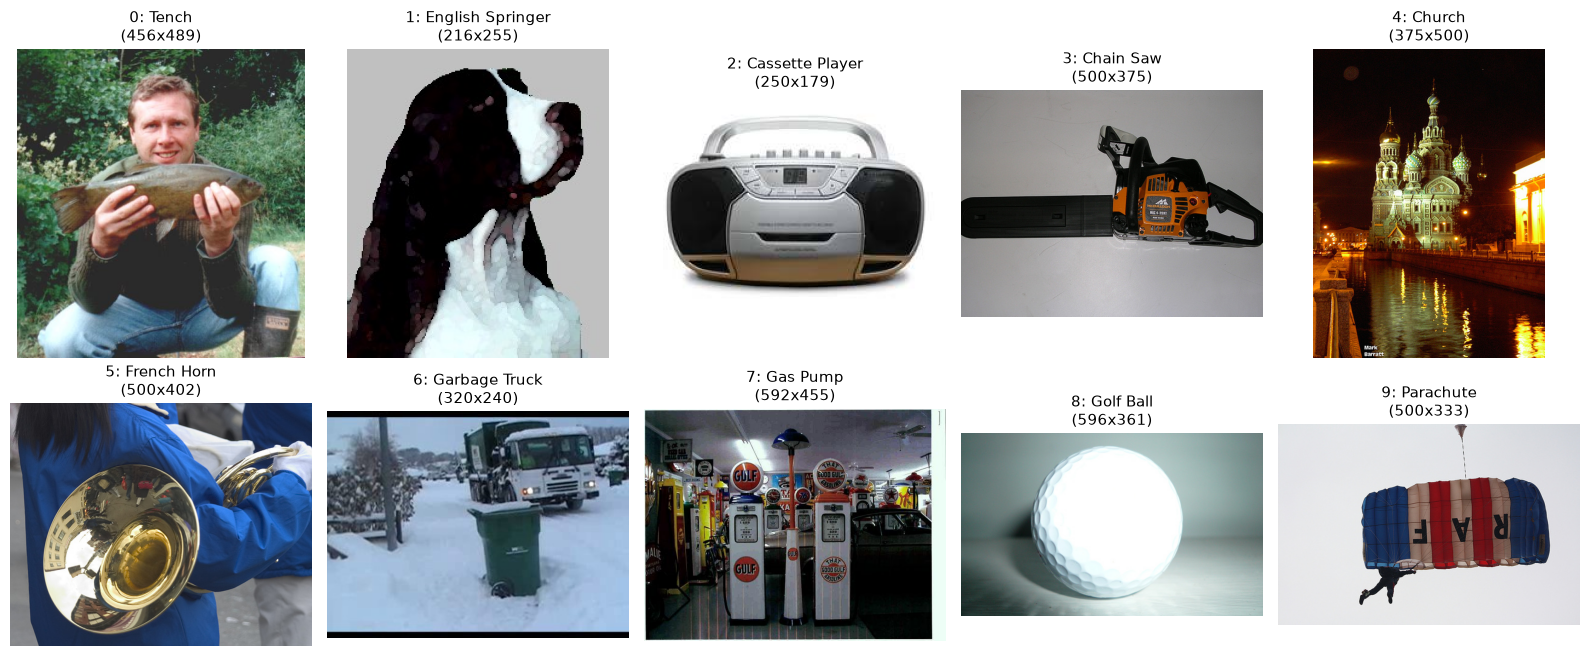

In [4]:
fig, axes = plt.subplots(2, 5, figsize=(16, 7))
axes = axes.ravel()

for idx in range(10):
    sample_row = train_df[train_df["label"] == idx].sample(1, random_state=SEED).iloc[0]
    img_bgr = cv2.imread(sample_row["path"])
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    
    axes[idx].imshow(img_rgb)
    axes[idx].set_title(f"{idx}: {sample_row['class_name']}\n({img_rgb.shape[1]}x{img_rgb.shape[0]})", fontsize=11)
    axes[idx].axis("off")

plt.tight_layout()
plt.show()

## 5. Preprocessing Utilities & Stratified K-Fold Setup
Based on our EDA findings (173 grayscale images and resolutions ranging from `50×27` to `4288×4368`), we define a **dual-resizing preprocessing strategy**:
- **Global Path (`128×128` RGB):** Standardizes spatial dimensions for fixed-length descriptors (Color grids, HOG, LBP, GLCM, FFT) while enforcing 3-channel RGB loading (`cv2.IMREAD_COLOR`).
- **Local Path (Aspect-Ratio Preserving, max side `320px`):** Preserves object geometry for keypoint detectors (RootSIFT in Phase 2B) without excessive memory overhead.

We also assign deterministic **Stratified 5-Fold Cross-Validation** indices on `train_df` so all ablation studies and hyperparameter tuning share identical splits.

In [5]:
from sklearn.model_selection import StratifiedKFold

# Preprocessing constants
GLOBAL_SIZE = (128, 128)
LOCAL_MAX_SIDE = 320
N_FOLDS = 5

def load_image_rgb(path: str) -> np.ndarray:
    """Loads any image (including 1-channel grayscale) strictly as 3-channel RGB."""
    img_bgr = cv2.imread(path, cv2.IMREAD_COLOR)
    if img_bgr is None:
        raise ValueError(f"Failed to read image: {path}")
    return cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

def resize_for_global(img_rgb: np.ndarray, size=GLOBAL_SIZE) -> np.ndarray:
    """Resizes image to fixed (W, H) for global descriptors."""
    interp = cv2.INTER_AREA if (img_rgb.shape[0] > size[1] or img_rgb.shape[1] > size[0]) else cv2.INTER_CUBIC
    return cv2.resize(img_rgb, size, interpolation=interp)

def resize_for_local(img_rgb: np.ndarray, max_side=LOCAL_MAX_SIDE) -> np.ndarray:
    """Resizes image preserving aspect ratio so the longest side <= max_side."""
    h, w = img_rgb.shape[:2]
    longest = max(h, w)
    if longest <= max_side:
        return img_rgb
    scale = max_side / longest
    new_w, new_h = int(round(w * scale)), int(round(h * scale))
    return cv2.resize(img_rgb, (new_w, new_h), interpolation=cv2.INTER_AREA)

# Assign deterministic Stratified 5-Fold indices on train_df
skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
train_df["fold"] = -1
for fold_idx, (_, val_idx) in enumerate(skf.split(train_df, train_df["label"])):
    train_df.loc[val_idx, "fold"] = fold_idx

print("Stratified 5-Fold distribution on train_df:")
display(pd.crosstab(train_df["fold"], train_df["label"]))

Stratified 5-Fold distribution on train_df:


label,0,1,2,3,4,5,6,7,8,9
fold,,,,,,,,,,
0,193,191,199,171,188,192,192,186,190,192
1,193,191,198,172,188,191,193,186,190,192
2,193,191,198,172,188,191,192,187,190,192
3,192,191,199,172,188,191,192,186,191,192
4,192,191,199,171,189,191,192,186,190,192


## 6. Classical Global Feature Extractors
We implement four distinct classical feature families so we can evaluate their individual and combined contributions in the upcoming Ablation Study:
1. **Color (`338` dims):** Global 3D HSV histogram (`8×4×4`), spatial `2×2` grid marginal histograms in HSV and CIELAB spaces, and color moments (mean, std, skewness).
2. **Shape & Edge (`1,784` dims):** HOG descriptors (`16×16` cells, `2×2` blocks, `9` orientations), spatial `2×2` Canny edge densities, Sobel orientation histogram, and log-transformed Hu Moments.
3. **Texture (`74` dims):** Multi-radius rotation-invariant Uniform LBP (`(P=8, R=1)`, `(16, 2)`, `(24, 3)`) and multi-distance GLCM statistics (contrast, dissimilarity, homogeneity, energy, correlation).
4. **Frequency (`40` dims):** Windowed 2D FFT log-magnitude spectrum summarized via 16 concentric radial frequency rings (mean & std) and 8 angular orientation wedges.

In [6]:
from scipy.stats import skew
from skimage.feature import hog, local_binary_pattern, graycomatrix, graycoprops

# Precompute 2D Hann window and polar coordinate grids for 128x128 FFT
_H, _W = GLOBAL_SIZE[1], GLOBAL_SIZE[0]
_HANN_2D = np.outer(np.hanning(_H), np.hanning(_W)).astype(np.float32)
_Y, _X = np.ogrid[:_H, :_W]
_CY, _CX = _H // 2, _W // 2
_RADIUS_MAP = np.sqrt((_X - _CX)**2 + (_Y - _CY)**2)
_ANGLE_MAP = (np.arctan2(_Y - _CY, _X - _CX) + np.pi) % np.pi  # [0, pi) due to FFT symmetry
_RADIAL_BINS = np.linspace(0, np.sqrt(_CX**2 + _CY**2) + 1e-5, 17)
_ANGLE_BINS = np.linspace(0, np.pi + 1e-5, 9)


def extract_color_features(img_rgb: np.ndarray) -> np.ndarray:
    """Extracts 338-dim Color feature vector (HSV + Lab)."""
    img_hsv = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2HSV)
    img_lab = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2LAB)
    feats = []

    # 1. Global 3D HSV histogram (8x4x4 = 128)
    hist_3d = cv2.calcHist([img_hsv], [0, 1, 2], None, [8, 4, 4], [0, 180, 0, 256, 0, 256]).flatten()
    hist_3d /= (hist_3d.sum() + 1e-7)
    feats.append(hist_3d)

    # 2. Spatial 2x2 grid 1D histograms in HSV & Lab (4 * 6 * 8 = 192)
    h, w = img_rgb.shape[:2]
    h_mid, w_mid = h // 2, w // 2
    slices = [(slice(0, h_mid), slice(0, w_mid)), (slice(0, h_mid), slice(w_mid, w)),
              (slice(h_mid, h), slice(0, w_mid)), (slice(h_mid, h), slice(w_mid, w))]
    
    for rs, cs in slices:
        hsv_q = img_hsv[rs, cs]
        lab_q = img_lab[rs, cs]
        for ch, max_val in [(0, 180), (1, 256), (2, 256)]:
            h1 = cv2.calcHist([hsv_q], [ch], None, [8], [0, max_val]).flatten()
            feats.append(h1 / (h1.sum() + 1e-7))
        for ch in range(3):
            h1 = cv2.calcHist([lab_q], [ch], None, [8], [0, 256]).flatten()
            feats.append(h1 / (h1.sum() + 1e-7))

    # 3. Color Moments (mean, std, skewness) for HSV & Lab (6 * 3 = 18)
    for space in (img_hsv, img_lab):
        for ch in range(3):
            vals = space[:, :, ch].astype(np.float32).ravel()
            m = vals.mean()
            s = vals.std()
            sk = float(skew(vals)) if s > 1e-5 else 0.0
            feats.append(np.array([m, s, sk], dtype=np.float32))

    return np.nan_to_num(np.concatenate(feats).astype(np.float32))


def extract_shape_features(img_gray: np.ndarray) -> np.ndarray:
    """Extracts 1,784-dim Shape & Edge feature vector (HOG + Canny + Sobel + Hu)."""
    # 1. HOG (7x7 blocks * 2x2 cells * 9 bins = 1764)
    hog_vec = hog(
        img_gray,
        orientations=9,
        pixels_per_cell=(16, 16),
        cells_per_block=(2, 2),
        block_norm="L2-Hys",
        feature_vector=True
    ).astype(np.float32)

    # 2. Canny edge density (global + 2x2 grid = 5)
    edges = cv2.Canny(img_gray, 100, 200) > 0
    h, w = img_gray.shape
    h_mid, w_mid = h // 2, w // 2
    canny_feats = np.array([
        edges.mean(),
        edges[:h_mid, :w_mid].mean(),
        edges[:h_mid, w_mid:].mean(),
        edges[h_mid:, :w_mid].mean(),
        edges[h_mid:, w_mid:].mean(),
    ], dtype=np.float32)

    # 3. Sobel gradient orientation histogram weighted by magnitude (8)
    gx = cv2.Sobel(img_gray, cv2.CV_32F, 1, 0, ksize=3)
    gy = cv2.Sobel(img_gray, cv2.CV_32F, 0, 1, ksize=3)
    mag = np.hypot(gx, gy)
    ang = (np.arctan2(gy, gx) + np.pi) % np.pi
    sobel_hist, _ = np.histogram(ang, bins=8, range=(0, np.pi), weights=mag)
    sobel_hist = (sobel_hist / (sobel_hist.sum() + 1e-7)).astype(np.float32)

    # 4. Log-transformed Hu Moments (7)
    hu = cv2.HuMoments(cv2.moments(img_gray)).flatten()
    hu_log = (-np.sign(hu) * np.log10(np.abs(hu) + 1e-12)).astype(np.float32)

    return np.nan_to_num(np.concatenate([hog_vec, canny_feats, sobel_hist, hu_log]))


def extract_texture_features(img_gray: np.ndarray) -> np.ndarray:
    """Extracts 74-dim Texture feature vector (Multi-radius Uniform LBP + GLCM)."""
    feats = []

    # 1. Multi-radius Uniform LBP (10 + 18 + 26 = 54)
    for P, R in [(8, 1), (16, 2), (24, 3)]:
        lbp = local_binary_pattern(img_gray, P=P, R=R, method="uniform")
        n_bins = P + 2
        hist, _ = np.histogram(lbp.ravel(), bins=n_bins, range=(0, n_bins), density=True)
        feats.append(hist.astype(np.float32))

    # 2. GLCM on 32 quantized levels (5 props * 2 distances * (mean, std) = 20)
    img_q = (img_gray // 8).astype(np.uint8)
    glcm = graycomatrix(
        img_q,
        distances=[1, 3],
        angles=[0, np.pi / 4, np.pi / 2, 3 * np.pi / 4],
        levels=32,
        symmetric=True,
        normed=True
    )
    for prop in ("contrast", "dissimilarity", "homogeneity", "energy", "correlation"):
        vals = graycoprops(glcm, prop)  # shape: (2 distances, 4 angles)
        feats.append(vals.mean(axis=1).astype(np.float32))
        feats.append(vals.std(axis=1).astype(np.float32))

    return np.nan_to_num(np.concatenate(feats))


def extract_frequency_features(img_gray: np.ndarray) -> np.ndarray:
    """Extracts 40-dim Frequency feature vector via windowed 2D FFT."""
    img_win = img_gray.astype(np.float32) * _HANN_2D
    fshift = np.fft.fftshift(np.fft.fft2(img_win))
    mag = np.log1p(np.abs(fshift))

    # 1. Radial ring statistics: 16 means + 16 stds = 32
    r_means, r_stds = [], []
    for i in range(16):
        mask = (_RADIUS_MAP >= _RADIAL_BINS[i]) & (_RADIUS_MAP < _RADIAL_BINS[i + 1])
        vals = mag[mask]
        r_means.append(vals.mean() if vals.size else 0.0)
        r_stds.append(vals.std() if vals.size else 0.0)

    # 2. Angular wedge means (excluding DC center r < 2): 8
    a_means = []
    non_dc = _RADIUS_MAP >= 2.0
    for i in range(8):
        mask = non_dc & (_ANGLE_MAP >= _ANGLE_BINS[i]) & (_ANGLE_MAP < _ANGLE_BINS[i + 1])
        vals = mag[mask]
        a_means.append(vals.mean() if vals.size else 0.0)

    return np.nan_to_num(np.array(r_means + r_stds + a_means, dtype=np.float32))


def extract_all_global_for_path(path: str):
    """Single-image worker extracting all 4 global feature families."""
    img_rgb = resize_for_global(load_image_rgb(path))
    img_gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    return (
        extract_color_features(img_rgb),
        extract_shape_features(img_gray),
        extract_texture_features(img_gray),
        extract_frequency_features(img_gray),
    )

# Quick sanity check on 1 image
_c, _s, _t, _f = extract_all_global_for_path(train_df["path"].iloc[0])
print(f"Sanity Check -> Color: {_c.shape}, Shape: {_s.shape}, Texture: {_t.shape}, Freq: {_f.shape}")

Sanity Check -> Color: (338,), Shape: (1784,), Texture: (74,), Freq: (40,)


## 7. Parallel Global Feature Extraction & Caching
To utilize all 8 logical CPU cores efficiently, we run global feature extraction in parallel using `joblib`. Extracted arrays are cached to `cache/global_features.npz` so downstream experiments (ablation studies, classifier tuning) can reload them instantaneously. Execution times are logged for the final hardware benchmark table.

In [7]:
from joblib import Parallel, delayed

USE_CACHE = True
GLOBAL_CACHE_PATH = CACHE_DIR / "global_features.npz"

def extract_global_split(paths, desc="Extracting"):
    t0 = time.perf_counter()
    results = Parallel(n_jobs=-1, prefer="processes")(
        delayed(extract_all_global_for_path)(p) for p in tqdm(paths, desc=desc)
    )
    elapsed = time.perf_counter() - t0
    X_color = np.vstack([r[0] for r in results])
    X_shape = np.vstack([r[1] for r in results])
    X_texture = np.vstack([r[2] for r in results])
    X_freq = np.vstack([r[3] for r in results])
    return X_color, X_shape, X_texture, X_freq, elapsed

if USE_CACHE and GLOBAL_CACHE_PATH.exists():
    print(f"Loading cached global features from {GLOBAL_CACHE_PATH}...")
    data = np.load(GLOBAL_CACHE_PATH)
    X_tr_color, X_tr_shape, X_tr_texture, X_tr_freq = data["tr_color"], data["tr_shape"], data["tr_texture"], data["tr_freq"]
    X_va_color, X_va_shape, X_va_texture, X_va_freq = data["va_color"], data["va_shape"], data["va_texture"], data["va_freq"]
    t_tr_global, t_va_global = float(data["t_tr"]), float(data["t_va"])
else:
    X_tr_color, X_tr_shape, X_tr_texture, X_tr_freq, t_tr_global = extract_global_split(train_df["path"], desc="Global Train")
    X_va_color, X_va_shape, X_va_texture, X_va_freq, t_va_global = extract_global_split(val_df["path"], desc="Global Val")
    np.savez_compressed(
        GLOBAL_CACHE_PATH,
        tr_color=X_tr_color, tr_shape=X_tr_shape, tr_texture=X_tr_texture, tr_freq=X_tr_freq,
        va_color=X_va_color, va_shape=X_va_shape, va_texture=X_va_texture, va_freq=X_va_freq,
        t_tr=t_tr_global, t_va=t_va_global
    )
    print(f"Saved global features to {GLOBAL_CACHE_PATH}")

print(f"\nGlobal Extraction Runtime -> Train: {t_tr_global:.2f}s | Val: {t_va_global:.2f}s")
print(f"Shapes (Train) -> Color: {X_tr_color.shape}, Shape: {X_tr_shape.shape}, Texture: {X_tr_texture.shape}, Freq: {X_tr_freq.shape}")
print(f"Shapes (Val)   -> Color: {X_va_color.shape}, Shape: {X_va_shape.shape}, Texture: {X_va_texture.shape}, Freq: {X_va_freq.shape}")

Loading cached global features from cache/global_features.npz...

Global Extraction Runtime -> Train: 107.76s | Val: 54.94s
Shapes (Train) -> Color: (9469, 338), Shape: (9469, 1784), Texture: (9469, 74), Freq: (9469, 40)
Shapes (Val)   -> Color: (3925, 338), Shape: (3925, 1784), Texture: (3925, 74), Freq: (3925, 40)


## 8. Local Keypoint Encoding: RootSIFT + Bag of Visual Words (BoVW)
To capture scale- and rotation-invariant local object parts (critical for cluttered backgrounds and viewpoint changes), we extract **RootSIFT** descriptors (*Arandjelović & Zisserman, CVPR 2012*) along the aspect-ratio-preserving local path (`max_side = 320px`, capped at `300` keypoints per image):
1. **RootSIFT Transformation:** Apply $L_1$ normalization followed by element-wise square root to standard SIFT descriptors so Euclidean distance corresponds to the Hellinger kernel.
2. **Visual Vocabulary (`MiniBatchKMeans`, $K=512$):** Trained **strictly on a random subset of `train` descriptors** (up to 300,000 descriptors) to prevent any data leakage from `val`.
3. **Histogram Encoding & Weighting:** Quantize each image's descriptors into a 512-bin visual word histogram, then apply **Sublinear TF-IDF** weighting and **$L_2$ normalization** (fitted strictly on `train`).

In [8]:
from sklearn.cluster import MiniBatchKMeans
from sklearn.feature_extraction.text import TfidfTransformer

BOVW_CACHE_PATH = CACHE_DIR / "bovw_features.npz"
N_CLUSTERS = 512
MAX_KEYPOINTS = 300
MAX_KMEANS_SAMPLES = 300_000


def extract_rootsift_for_path(path: str) -> np.ndarray:
    """Extracts RootSIFT descriptors (N, 128) along the aspect-preserving local path."""
    img_rgb = resize_for_local(load_image_rgb(path), max_side=LOCAL_MAX_SIDE)
    img_gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)

    sift = cv2.SIFT_create(nfeatures=MAX_KEYPOINTS)
    _, des = sift.detectAndCompute(img_gray, None)

    if des is None or len(des) == 0:
        return np.empty((0, 128), dtype=np.float32)

    # RootSIFT: L1 normalize then element-wise square root
    des = des.astype(np.float32)
    des /= (des.sum(axis=1, keepdims=True) + 1e-7)
    des = np.sqrt(des)
    return des


def encode_bovw_histograms(desc_list, kmeans: MiniBatchKMeans, n_clusters: int) -> np.ndarray:
    """Quantizes a list of per-image descriptor arrays into raw BoVW histograms."""
    hists = np.zeros((len(desc_list), n_clusters), dtype=np.float32)
    for i, des in enumerate(desc_list):
        if len(des) > 0:
            words = kmeans.predict(des)
            hists[i] = np.bincount(words, minlength=n_clusters)
    return hists


if USE_CACHE and BOVW_CACHE_PATH.exists():
    print(f"Loading cached BoVW features from {BOVW_CACHE_PATH}...")
    bovw_data = np.load(BOVW_CACHE_PATH)
    X_tr_bovw = bovw_data["tr_bovw"]
    X_va_bovw = bovw_data["va_bovw"]
    t_tr_bovw = float(bovw_data["t_tr"])
    t_va_bovw = float(bovw_data["t_va"])
else:
    # --- Train Phase (Extract + Fit KMeans + Encode + Fit TF-IDF) ---
    t0_tr = time.perf_counter()

    tr_descs = Parallel(n_jobs=-1, prefer="processes")(
        delayed(extract_rootsift_for_path)(p) for p in tqdm(train_df["path"], desc="RootSIFT Train")
    )
    empty_tr = sum(len(d) == 0 for d in tr_descs)

    # Stack and subsample descriptors strictly from Train for K-Means vocabulary
    all_tr_descs = np.vstack([d for d in tr_descs if len(d) > 0])
    print(f"Total Train RootSIFT descriptors: {len(all_tr_descs):,} (images with 0 keypoints: {empty_tr})")

    rng = np.random.default_rng(SEED)
    if len(all_tr_descs) > MAX_KMEANS_SAMPLES:
        sample_idx = rng.choice(len(all_tr_descs), size=MAX_KMEANS_SAMPLES, replace=False)
        kmeans_input = all_tr_descs[sample_idx]
    else:
        kmeans_input = all_tr_descs

    print(f"Fitting MiniBatchKMeans (K={N_CLUSTERS}) on {len(kmeans_input):,} train descriptors...")
    kmeans = MiniBatchKMeans(
        n_clusters=N_CLUSTERS,
        batch_size=4096,
        random_state=SEED,
        n_init=3,
        max_iter=150,
    )
    kmeans.fit(kmeans_input)
    del all_tr_descs, kmeans_input  # Free RAM

    X_tr_bovw_raw = encode_bovw_histograms(tr_descs, kmeans, N_CLUSTERS)
    del tr_descs

    tfidf = TfidfTransformer(norm="l2", use_idf=True, smooth_idf=True, sublinear_tf=True)
    X_tr_bovw = tfidf.fit_transform(X_tr_bovw_raw).toarray().astype(np.float32)
    t_tr_bovw = time.perf_counter() - t0_tr

    # --- Val Phase (Extract + Transform Only — Zero Leakage) ---
    t0_va = time.perf_counter()

    va_descs = Parallel(n_jobs=-1, prefer="processes")(
        delayed(extract_rootsift_for_path)(p) for p in tqdm(val_df["path"], desc="RootSIFT Val")
    )
    empty_va = sum(len(d) == 0 for d in va_descs)
    print(f"Val images with 0 keypoints: {empty_va}")

    X_va_bovw_raw = encode_bovw_histograms(va_descs, kmeans, N_CLUSTERS)
    del va_descs

    X_va_bovw = tfidf.transform(X_va_bovw_raw).toarray().astype(np.float32)
    t_va_bovw = time.perf_counter() - t0_va

    np.savez_compressed(
        BOVW_CACHE_PATH,
        tr_bovw=X_tr_bovw,
        va_bovw=X_va_bovw,
        t_tr=t_tr_bovw,
        t_va=t_va_bovw,
    )
    print(f"Saved BoVW features to {BOVW_CACHE_PATH}")

print(f"\nBoVW Runtime -> Train (extract + fit + encode): {t_tr_bovw:.2f}s | Val (extract + encode): {t_va_bovw:.2f}s")
print(f"BoVW Shapes  -> Train: {X_tr_bovw.shape} | Val: {X_va_bovw.shape}")

Loading cached BoVW features from cache/bovw_features.npz...

BoVW Runtime -> Train (extract + fit + encode): 100.10s | Val (extract + encode): 55.36s
BoVW Shapes  -> Train: (9469, 512) | Val: (3925, 512)


## 9. Multi-Modal Feature Fusion & Leakage-Free Scaling Pipeline
Our five classical feature families span very different dimensionalities—from `40` dims (Frequency) up to `1,784` dims (Shape/HOG). Direct concatenation with standard scaling alone would allow high-dimensional blocks to dominate distance and dot-product computations.

To ensure balanced multi-modal fusion with **zero data leakage**:
1. Each feature family is scaled independently using `StandardScaler` **fitted strictly on the training fold**.
2. Each scaled block is then **$L_2$-normalized** per sample (block-wise normalization) before horizontal concatenation so every feature family contributes on a comparable scale.
3. All Ablation Study experiments are evaluated strictly via our deterministic **Stratified 5-Fold Cross-Validation** on `train_df`, keeping `val_df` completely untouched.

In [9]:
from sklearn.preprocessing import StandardScaler, normalize
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

# Organize all 5 feature families (Train for CV/Ablation; Val strictly quarantined)
TRAIN_FEATURES = {
    "Color": X_tr_color,
    "Shape": X_tr_shape,
    "Texture": X_tr_texture,
    "Frequency": X_tr_freq,
    "BoVW": X_tr_bovw,
}

VAL_FEATURES = {
    "Color": X_va_color,
    "Shape": X_va_shape,
    "Texture": X_va_texture,
    "Frequency": X_va_freq,
    "BoVW": X_va_bovw,
}

y_train = train_df["label"].values
y_val = val_df["label"].values
folds = train_df["fold"].values

print("Feature Family Dimensions:")
total_dims = 0
for name, mat in TRAIN_FEATURES.items():
    print(f"  - {name:<10}: {mat.shape[1]:>5} dims")
    total_dims += mat.shape[1]
print(f"  - {'TOTAL':<10}: {total_dims:>5} dims")


def fuse_blocks_fit_transform(feature_dict, family_names, idx_tr, idx_va):
    """Fits per-family StandardScaler strictly on idx_tr, applies block-wise L2 norm, and concatenates."""
    tr_blocks, va_blocks = [], []
    for name in family_names:
        X = feature_dict[name]
        scaler = StandardScaler()
        X_tr_s = scaler.fit_transform(X[idx_tr])
        X_va_s = scaler.transform(X[idx_va])

        # Block-wise L2 normalization balances contributions across different dimensionalities
        tr_blocks.append(normalize(X_tr_s, norm="l2", axis=1))
        va_blocks.append(normalize(X_va_s, norm="l2", axis=1))

    return np.hstack(tr_blocks).astype(np.float32), np.hstack(va_blocks).astype(np.float32)


def evaluate_feature_subset_cv(family_names, C=2.0):
    """Evaluates a subset of feature families using 5-Fold Stratified CV with a fixed linear probe."""
    fold_accs, fold_f1s = [], []
    t0 = time.perf_counter()

    for f in range(N_FOLDS):
        tr_idx = np.where(folds != f)[0]
        va_idx = np.where(folds == f)[0]

        X_tr_f, X_va_f = fuse_blocks_fit_transform(TRAIN_FEATURES, family_names, tr_idx, va_idx)

        clf = LogisticRegression(
            C=C,
            solver="lbfgs",
            max_iter=500,
            random_state=SEED
        )
        clf.fit(X_tr_f, y_train[tr_idx])
        preds = clf.predict(X_va_f)

        fold_accs.append(accuracy_score(y_train[va_idx], preds))
        fold_f1s.append(f1_score(y_train[va_idx], preds, average="macro"))

    elapsed = time.perf_counter() - t0
    return {
        "families": " + ".join(family_names),
        "n_dims": sum(TRAIN_FEATURES[n].shape[1] for n in family_names),
        "acc_mean": float(np.mean(fold_accs)),
        "acc_std": float(np.std(fold_accs)),
        "f1_mean": float(np.mean(fold_f1s)),
        "f1_std": float(np.std(fold_f1s)),
        "cv_time_s": round(elapsed, 2),
    }

Feature Family Dimensions:
  - Color     :   338 dims
  - Shape     :  1784 dims
  - Texture   :    74 dims
  - Frequency :    40 dims
  - BoVW      :   512 dims
  - TOTAL     :  2748 dims


## 10. Systematic Ablation Study (Individual, Forward Addition & Leave-One-Out)
To quantify the exact predictive value of each classical feature family, we conduct a three-part Ablation Study using a fixed `LogisticRegression` probe across all 5 training folds:
1. **Individual Family Evaluation:** Measures standalone discriminative power of each family.
2. **Forward Addition:** Starts from the strongest individual family and cumulatively adds the remaining families in descending order of standalone accuracy.
3. **Leave-One-Out (LOO):** Starts from the full 5-family fused vector and drops one family at a time to measure its marginal contribution ($\Delta$ Accuracy).

We summarize the results in comparative tables and generate a high-resolution summary figure for the final report.

Running Part 1: Individual Feature Families...


,family,n_dims,acc_mean,acc_std,f1_mean,cv_time_s
0,Shape,1784,0.578098,0.009463,0.571867,87.70
1,BoVW,512,0.550006,0.013526,0.543766,29.08
2,Texture,74,0.521385,0.008110,0.511526,12.88
3,Color,338,0.474391,0.009952,0.467990,38.09
4,Frequency,40,0.442391,0.006058,0.426429,6.21



Running Part 2: Forward Addition...


,step,families,n_dims,acc_mean,acc_std,f1_mean,cv_time_s
0,Shape,Shape,1784,0.578098,0.009463,0.571867,94.09
1,+ BoVW,Shape + BoVW,2296,0.690148,0.006362,0.686925,82.50
2,+ Texture,Shape + BoVW + Texture,2370,0.724787,0.004061,0.722212,80.18
3,+ Color,Shape + BoVW + Texture + Color,2708,0.770831,0.007757,0.768326,68.32
4,+ Frequency,Shape + BoVW + Texture + Color + Frequency,2748,0.777274,0.004531,0.774881,74.33



Running Part 3: Leave-One-Out (LOO)...


,removed_family,n_dims,acc_mean,delta_acc,f1_mean,delta_f1,cv_time_s
0,Color,2410,0.737249,-0.040025,0.734952,-0.039929,81.10
1,Shape,964,0.737882,-0.039392,0.734948,-0.039932,35.83
2,BoVW,2236,0.739783,-0.037491,0.736898,-0.037982,80.95
3,Texture,2674,0.765234,-0.012040,0.762460,-0.012421,72.60
4,Frequency,2708,0.770937,-0.006337,0.768420,-0.006461,71.11


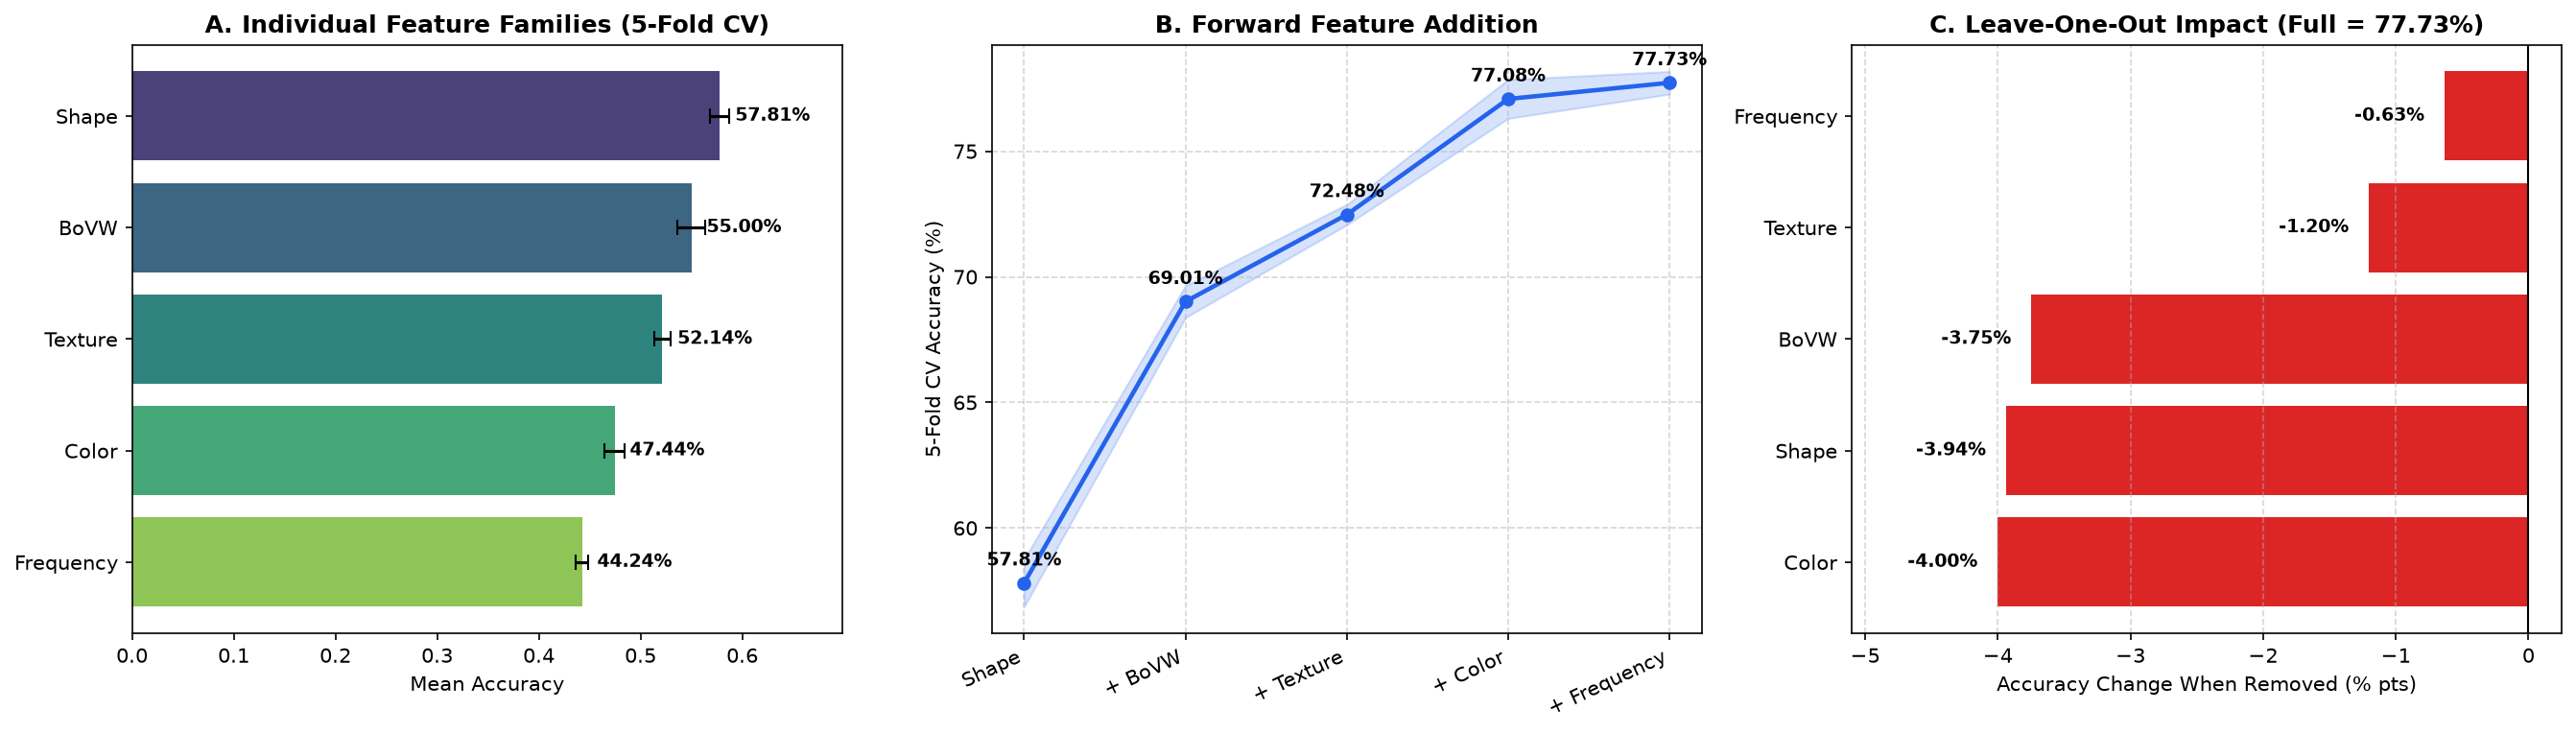

In [10]:
ALL_FAMILIES = list(TRAIN_FEATURES.keys())

# 1. Individual Family Performance
print("Running Part 1: Individual Feature Families...")
indiv_rows = []
for fam in ALL_FAMILIES:
    res = evaluate_feature_subset_cv([fam])
    res["family"] = fam
    indiv_rows.append(res)

indiv_df = pd.DataFrame(indiv_rows).sort_values("acc_mean", ascending=False).reset_index(drop=True)
display(indiv_df[["family", "n_dims", "acc_mean", "acc_std", "f1_mean", "cv_time_s"]])

# 2. Forward Addition (ranked by individual performance)
print("\nRunning Part 2: Forward Addition...")
ranked_families = indiv_df["family"].tolist()
fwd_rows = []
current_subset = []
for fam in ranked_families:
    current_subset.append(fam)
    res = evaluate_feature_subset_cv(current_subset)
    res["step"] = f"+ {fam}" if len(current_subset) > 1 else fam
    fwd_rows.append(res)

fwd_df = pd.DataFrame(fwd_rows)
display(fwd_df[["step", "families", "n_dims", "acc_mean", "acc_std", "f1_mean", "cv_time_s"]])

# 3. Leave-One-Out (LOO) from Full Fused Vector
print("\nRunning Part 3: Leave-One-Out (LOO)...")
full_acc = fwd_df.iloc[-1]["acc_mean"]
full_f1 = fwd_df.iloc[-1]["f1_mean"]

loo_rows = []
for fam in ALL_FAMILIES:
    subset = [f for f in ALL_FAMILIES if f != fam]
    res = evaluate_feature_subset_cv(subset)
    res["removed_family"] = fam
    res["delta_acc"] = res["acc_mean"] - full_acc  # Negative means accuracy dropped when removed
    res["delta_f1"] = res["f1_mean"] - full_f1
    loo_rows.append(res)

loo_df = pd.DataFrame(loo_rows).sort_values("delta_acc", ascending=True).reset_index(drop=True)
display(loo_df[["removed_family", "n_dims", "acc_mean", "delta_acc", "f1_mean", "delta_f1", "cv_time_s"]])

# --- Visualization (3-Panel Ablation Figure for Report) ---
fig, axes = plt.subplots(1, 3, figsize=(18, 5.2), dpi=150)

# Panel A: Individual Families
sns.barplot(data=indiv_df, x="acc_mean", y="family", hue="family", palette="viridis", legend=False, ax=axes[0])
axes[0].errorbar(indiv_df["acc_mean"], range(len(indiv_df)), xerr=indiv_df["acc_std"], fmt="none", c="black", capsize=4)
axes[0].set_title("A. Individual Feature Families (5-Fold CV)", fontweight="bold")
axes[0].set_xlabel("Mean Accuracy")
axes[0].set_ylabel("")
axes[0].set_xlim(0, max(indiv_df["acc_mean"]) + 0.12)
for i, v in enumerate(indiv_df["acc_mean"]):
    axes[0].text(v + 0.015, i, f"{v*100:.2f}%", va="center", fontsize=9, fontweight="bold")

# Panel B: Forward Addition Curve
x_steps = range(len(fwd_df))
axes[1].plot(x_steps, fwd_df["acc_mean"] * 100, marker="o", linewidth=2.2, color="#2563EB")
axes[1].fill_between(
    x_steps,
    (fwd_df["acc_mean"] - fwd_df["acc_std"]) * 100,
    (fwd_df["acc_mean"] + fwd_df["acc_std"]) * 100,
    alpha=0.18, color="#2563EB"
)
axes[1].set_xticks(x_steps)
axes[1].set_xticklabels(fwd_df["step"], rotation=25, ha="right")
axes[1].set_title("B. Forward Feature Addition", fontweight="bold")
axes[1].set_ylabel("5-Fold CV Accuracy (%)")
axes[1].grid(True, linestyle="--", alpha=0.5)
for i, v in enumerate(fwd_df["acc_mean"] * 100):
    axes[1].text(i, v + 0.7, f"{v:.2f}%", ha="center", fontsize=9, fontweight="bold")

# Panel C: Leave-One-Out Delta Accuracy
colors_loo = ["#DC2626" if d < 0 else "#16A34A" for d in loo_df["delta_acc"]]
axes[2].barh(loo_df["removed_family"], loo_df["delta_acc"] * 100, color=colors_loo)
axes[2].axvline(0, color="black", linewidth=1.0)
axes[2].set_title(f"C. Leave-One-Out Impact (Full = {full_acc*100:.2f}%)", fontweight="bold")
axes[2].set_xlabel("Accuracy Change When Removed (% pts)")
axes[2].grid(axis="x", linestyle="--", alpha=0.5)
for i, d in enumerate(loo_df["delta_acc"] * 100):
    offset = -0.15 if d < 0 else 0.15
    ha = "right" if d < 0 else "left"
    axes[2].text(d + offset, i, f"{d:+.2f}%", va="center", ha=ha, fontsize=9, fontweight="bold")
    axes[2].set_xlim(min(loo_df["delta_acc"] * 100) - 1.1, 0.25)
plt.tight_layout()
os.makedirs("assets", exist_ok=True)
plt.savefig("assets/ablation_study.png", dpi=200, bbox_inches="tight")
plt.show()

## 11. Classical Classifier Benchmarking (5-Fold Stratified CV)
Using the full 5-family fused representation (`2,748` dims) with leakage-free block-wise scaling fitted inside each training fold, we benchmark seven diverse classical machine learning classifiers:
- **Linear & Kernel Models:** `LogisticRegression`, `SVM (RBF Kernel)`
- **Instance-Based:** `k-NN` (Cosine Distance)
- **Tree Ensembles:** `Random Forest`, `Extra Trees`, `LightGBM`, `XGBoost`

For every model, we log 5-Fold CV Accuracy, Macro F1-Score, total training time, and inference time to guide hyperparameter tuning and ensemble design.

Precomputing leakage-free fused folds for classifier benchmarking...
Logistic Regression    -> Acc: 77.61% (±0.43%) | F1: 77.37% | Fit: 69.08s
SVM (RBF)              -> Acc: 79.40% (±0.62%) | F1: 79.22% | Fit: 334.09s
k-NN (Cosine, k=11)    -> Acc: 65.50% (±0.72%) | F1: 64.96% | Fit: 0.05s
Random Forest          -> Acc: 66.25% (±0.57%) | F1: 65.52% | Fit: 90.09s
Extra Trees            -> Acc: 67.13% (±0.90%) | F1: 66.32% | Fit: 43.06s
LightGBM               -> Acc: 78.37% (±0.96%) | F1: 78.15% | Fit: 733.71s


sh: 1: nvidia-smi: not found


XGBoost                -> Acc: 77.54% (±0.74%) | F1: 77.35% | Fit: 2243.46s


,Model,CV Accuracy,Acc Std,CV Macro F1,Train Time (5-fold s),Infer Time (5-fold s)
0,SVM (RBF),0.793960,0.006175,0.792246,334.09,104.48
1,LightGBM,0.783716,0.009598,0.781503,733.71,0.95
2,Logistic Regression,0.776112,0.004305,0.773660,69.08,0.05
3,XGBoost,0.775372,0.007447,0.773494,2243.46,0.15
4,Extra Trees,0.671349,0.009017,0.663177,43.06,0.69
5,Random Forest,0.662477,0.005743,0.655249,90.09,0.43
6,"k-NN (Cosine, k=11)",0.654979,0.007179,0.649619,0.05,2.34


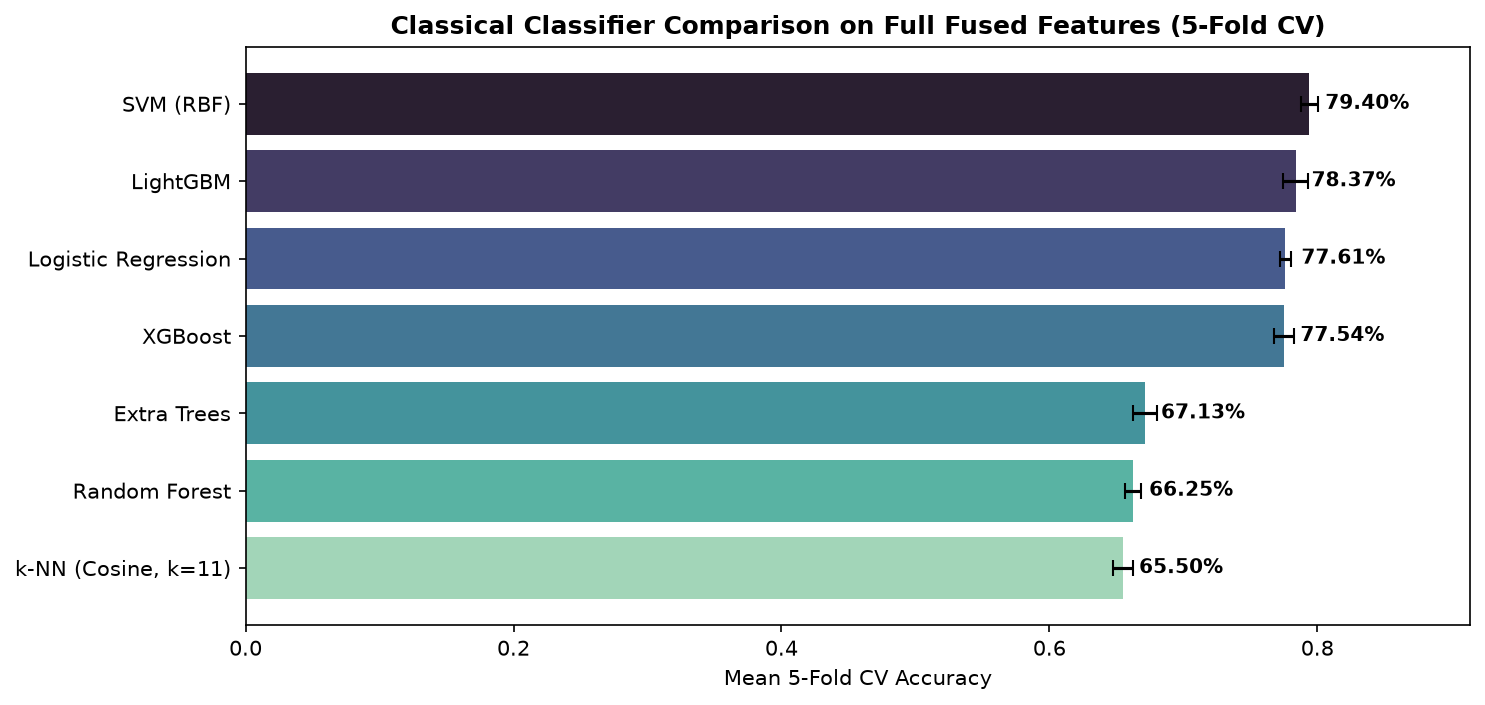

In [11]:
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier

# Precompute fold-wise fused matrices once so all classifiers train on identical leakage-free folds
print("Precomputing leakage-free fused folds for classifier benchmarking...")
FOLD_DATA = []
for f in range(N_FOLDS):
    tr_idx = np.where(folds != f)[0]
    va_idx = np.where(folds == f)[0]
    X_tr_f, X_va_f = fuse_blocks_fit_transform(TRAIN_FEATURES, ALL_FAMILIES, tr_idx, va_idx)
    FOLD_DATA.append((X_tr_f, y_train[tr_idx], X_va_f, y_train[va_idx], va_idx))


def get_benchmark_models():
    return {
        "Logistic Regression": lambda: LogisticRegression(
            C=2.0, solver="lbfgs", max_iter=500, random_state=SEED
        ),
        "SVM (RBF)": lambda: SVC(
            C=3.0, kernel="rbf", gamma="scale", random_state=SEED
        ),
        "k-NN (Cosine, k=11)": lambda: KNeighborsClassifier(
            n_neighbors=11, metric="cosine", weights="distance", n_jobs=-1
        ),
        "Random Forest": lambda: RandomForestClassifier(
            n_estimators=300, max_features="sqrt", n_jobs=-1, random_state=SEED
        ),
        "Extra Trees": lambda: ExtraTreesClassifier(
            n_estimators=400, max_features="sqrt", n_jobs=-1, random_state=SEED
        ),
        "LightGBM": lambda: LGBMClassifier(
            n_estimators=400, learning_rate=0.05, num_leaves=31,
            subsample_for_bin=50000, colsample_bytree=0.3, subsample=0.8,
            n_jobs=-1, random_state=SEED, verbose=-1
        ),
        "XGBoost": lambda: XGBClassifier(
            n_estimators=350, learning_rate=0.06, max_depth=5,
            colsample_bytree=0.25, subsample=0.8, tree_method="hist",
            n_jobs=-1, random_state=SEED, eval_metric="mlogloss"
        ),
    }


bench_rows = []
for model_name, model_fn in get_benchmark_models().items():
    accs, f1s = [], []
    fit_time, pred_time = 0.0, 0.0

    for X_tr_f, y_tr_f, X_va_f, y_va_f, _ in FOLD_DATA:
        clf = model_fn()

        t0 = time.perf_counter()
        clf.fit(X_tr_f, y_tr_f)
        fit_time += time.perf_counter() - t0

        t1 = time.perf_counter()
        preds = clf.predict(X_va_f)
        pred_time += time.perf_counter() - t1

        accs.append(accuracy_score(y_va_f, preds))
        f1s.append(f1_score(y_va_f, preds, average="macro"))

    row = {
        "Model": model_name,
        "CV Accuracy": float(np.mean(accs)),
        "Acc Std": float(np.std(accs)),
        "CV Macro F1": float(np.mean(f1s)),
        "Train Time (5-fold s)": round(fit_time, 2),
        "Infer Time (5-fold s)": round(pred_time, 2),
    }
    bench_rows.append(row)
    print(f"{model_name:<22} -> Acc: {row['CV Accuracy']*100:.2f}% (±{row['Acc Std']*100:.2f}%) | "
          f"F1: {row['CV Macro F1']*100:.2f}% | Fit: {row['Train Time (5-fold s)']}s")

bench_df = pd.DataFrame(bench_rows).sort_values("CV Accuracy", ascending=False).reset_index(drop=True)
display(bench_df)

# Save benchmark chart for report
fig, ax = plt.subplots(figsize=(10, 4.8), dpi=150)
sns.barplot(data=bench_df, x="CV Accuracy", y="Model", hue="Model", palette="mako", legend=False, ax=ax)
ax.errorbar(bench_df["CV Accuracy"], range(len(bench_df)), xerr=bench_df["Acc Std"], fmt="none", c="black", capsize=4)
ax.set_xlim(0, min(1.0, bench_df["CV Accuracy"].max() + 0.12))
ax.set_title("Classical Classifier Comparison on Full Fused Features (5-Fold CV)", fontweight="bold")
ax.set_xlabel("Mean 5-Fold CV Accuracy")
ax.set_ylabel("")
for i, v in enumerate(bench_df["CV Accuracy"]):
    ax.text(v + 0.012, i, f"{v*100:.2f}%", va="center", fontsize=9.5, fontweight="bold")
plt.tight_layout()
plt.savefig("assets/classifier_benchmark.png", dpi=200, bbox_inches="tight")
plt.show()

## 12. Hyperparameter Tuning, Block Weighting & Classical Ensembling
Guided by our benchmark results, we discard `XGBoost` (high 36-minute CPU cost with lower accuracy than `LightGBM`) and the weaker baselines (`RF`, `ExtraTrees`, `k-NN`), focusing on the top three structurally diverse model families:
1. **Kernel-based:** `SVM (RBF)` — highest standalone accuracy (`79.40%`).
2. **Gradient Boosted Trees:** `LightGBM` — strong non-linear tree learner (`78.37%`).
3. **Linear:** `Logistic Regression` — lowest variance (`±0.43%`) and well-calibrated probabilities.

We first test **ablation-informed block weighting** (giving higher $L_2$ energy to `Color`, `Shape`, and `BoVW` relative to `Texture` and `Frequency`) and tune `SVM (RBF)` (`C`) and `LogisticRegression` (`C`) via 5-Fold CV. Finally, we collect Out-of-Fold (OOF) predictions from all three tuned base models and compare **Weighted Soft Voting** against a **Stacking Meta-Learner** (`LogisticRegression`) evaluated strictly inside 5-Fold CV.

In [12]:
from sklearn.metrics import log_loss

# Compute exact column slices for each feature family inside FOLD_DATA
BLOCK_SLICES = {}
_cursor = 0
for fam in ALL_FAMILIES:
    dim = TRAIN_FEATURES[fam].shape[1]
    BLOCK_SLICES[fam] = slice(_cursor, _cursor + dim)
    _cursor += dim

def apply_block_weights(X: np.ndarray, weights: dict) -> np.ndarray:
    """Scales each pre-L2-normalized feature block by its assigned weight."""
    X_w = X.copy()
    for fam, w in weights.items():
        if w != 1.0:
            X_w[:, BLOCK_SLICES[fam]] *= np.float32(w)
    return X_w

# ---------------------------------------------------------
# 1. Tune SVM (RBF): Block Weighting + Regularization C
# ---------------------------------------------------------
UNIFORM_W = {f: 1.0 for f in ALL_FAMILIES}
ABLATION_W = {"Color": 1.25, "Shape": 1.25, "BoVW": 1.30, "Texture": 0.80, "Frequency": 0.60}

svm_configs = [
    ("Uniform_W | C=3.0",  UNIFORM_W,  3.0),
    ("Uniform_W | C=5.0",  UNIFORM_W,  5.0),
    ("Ablation_W | C=3.0", ABLATION_W, 3.0),
    ("Ablation_W | C=5.0", ABLATION_W, 5.0),
    ("Ablation_W | C=7.0", ABLATION_W, 7.0),
]

def _run_svm_fold(fold_tuple, weights, C):
    X_tr_f, y_tr_f, X_va_f, y_va_f, va_idx = fold_tuple
    X_tr_w = apply_block_weights(X_tr_f, weights)
    X_va_w = apply_block_weights(X_va_f, weights)
    clf = SVC(C=C, kernel="rbf", gamma="scale", decision_function_shape="ovr", random_state=SEED)
    clf.fit(X_tr_w, y_tr_f)
    margins = clf.decision_function(X_va_w)
    preds = np.argmax(margins, axis=1)
    return va_idx, margins, accuracy_score(y_va_f, preds), f1_score(y_va_f, preds, average="macro")

print("=== Step 12A: Tuning SVM (RBF) & Block Weights (Parallel 5-Fold CV) ===")
svm_results = []
best_svm_acc = -1.0
best_svm_cfg = None
oof_svm_margins = np.zeros((len(train_df), 10), dtype=np.float32)

for cfg_name, w_dict, C_val in svm_configs:
    t0 = time.perf_counter()
    fold_out = Parallel(n_jobs=4, prefer="processes")(
        delayed(_run_svm_fold)(ft, w_dict, C_val) for ft in FOLD_DATA
    )
    elapsed = time.perf_counter() - t0
    accs = [o[2] for o in fold_out]
    f1s = [o[3] for o in fold_out]
    mean_acc, std_acc, mean_f1 = float(np.mean(accs)), float(np.std(accs)), float(np.mean(f1s))
    svm_results.append({"Config": cfg_name, "CV Acc": mean_acc, "Std": std_acc, "CV F1": mean_f1, "Time (s)": round(elapsed, 1)})
    print(f"  {cfg_name:<20} -> Acc: {mean_acc*100:.2f}% (±{std_acc*100:.2f}%) | F1: {mean_f1*100:.2f}% | {elapsed:.1f}s")

    if mean_acc > best_svm_acc:
        best_svm_acc = mean_acc
        best_svm_cfg = (cfg_name, w_dict, C_val)
        for va_idx, margins, _, _ in fold_out:
            oof_svm_margins[va_idx] = margins

BEST_WEIGHTS = best_svm_cfg[1]
BEST_SVM_C = best_svm_cfg[2]
print(f"--> Selected Best SVM: {best_svm_cfg[0]} (Acc: {best_svm_acc*100:.2f}%)\n")

# ---------------------------------------------------------
# 2. Tune Logistic Regression (C) using Best Block Weights
# ---------------------------------------------------------
print("=== Step 12B: Tuning Logistic Regression (5-Fold CV) ===")
best_lr_acc = -1.0
BEST_LR_C = 2.0
oof_lr_proba = np.zeros((len(train_df), 10), dtype=np.float32)

for C_val in [0.5, 1.0, 2.0, 4.0]:
    accs = []
    tmp_oof = np.zeros((len(train_df), 10), dtype=np.float32)
    for X_tr_f, y_tr_f, X_va_f, y_va_f, va_idx in FOLD_DATA:
        clf = LogisticRegression(C=C_val, solver="lbfgs", max_iter=600, random_state=SEED)
        clf.fit(apply_block_weights(X_tr_f, BEST_WEIGHTS), y_tr_f)
        probs = clf.predict_proba(apply_block_weights(X_va_f, BEST_WEIGHTS))
        tmp_oof[va_idx] = probs
        accs.append(accuracy_score(y_va_f, np.argmax(probs, axis=1)))
    mean_acc = float(np.mean(accs))
    print(f"  LogReg C={C_val:<4} -> Acc: {mean_acc*100:.2f}% (±{np.std(accs)*100:.2f}%)")
    if mean_acc > best_lr_acc:
        best_lr_acc = mean_acc
        BEST_LR_C = C_val
        oof_lr_proba = tmp_oof

print(f"--> Selected Best LogReg: C={BEST_LR_C} (Acc: {best_lr_acc*100:.2f}%)\n")

# ---------------------------------------------------------
# 3. Collect OOF Probabilities from Tuned LightGBM
# ---------------------------------------------------------
print("=== Step 12C: Training Tuned LightGBM for OOF Ensemble Predictions ===")
t0 = time.perf_counter()
oof_lgbm_proba = np.zeros((len(train_df), 10), dtype=np.float32)
lgbm_accs = []
LGBM_PARAMS = dict(
    n_estimators=500, learning_rate=0.045, num_leaves=31,
    colsample_bytree=0.25, subsample=0.8, subsample_freq=1,
    reg_lambda=1.0, n_jobs=-1, random_state=SEED, verbose=-1
)

for X_tr_f, y_tr_f, X_va_f, y_va_f, va_idx in FOLD_DATA:
    clf = LGBMClassifier(**LGBM_PARAMS)
    clf.fit(X_tr_f, y_tr_f)
    probs = clf.predict_proba(X_va_f)
    oof_lgbm_proba[va_idx] = probs
    lgbm_accs.append(accuracy_score(y_va_f, np.argmax(probs, axis=1)))

print(f"  Tuned LightGBM -> Acc: {np.mean(lgbm_accs)*100:.2f}% (±{np.std(lgbm_accs)*100:.2f}%) | {time.perf_counter()-t0:.1f}s\n")

# ---------------------------------------------------------
# 4. Classical Ensembling: Soft Voting vs. Stacking (Strict 5-Fold OOF CV)
# ---------------------------------------------------------
print("=== Step 12D: Classical Ensemble Comparison (5-Fold CV) ===")

# Calibrate SVM margins into probabilities strictly out-of-fold (zero leakage)
oof_svm_proba = np.zeros_like(oof_svm_margins)
for f in range(N_FOLDS):
    tr_idx = np.where(folds != f)[0]
    va_idx = np.where(folds == f)[0]
    cal = LogisticRegression(C=1.0, max_iter=500, random_state=SEED)
    cal.fit(oof_svm_margins[tr_idx], y_train[tr_idx])
    oof_svm_proba[va_idx] = cal.predict_proba(oof_svm_margins[va_idx])

# A. Weighted Soft Voting (search weights on OOF)
best_vote_acc = -1.0
BEST_VOTE_WEIGHTS = (0.5, 0.3, 0.2)
for w_svm in [0.4, 0.5, 0.6]:
    for w_lgb in [0.2, 0.3, 0.4]:
        w_lr = round(1.0 - w_svm - w_lgb, 2)
        if w_lr < 0.05:
            continue
        blend = w_svm * oof_svm_proba + w_lgb * oof_lgbm_proba + w_lr * oof_lr_proba
        acc = accuracy_score(y_train, np.argmax(blend, axis=1))
        if acc > best_vote_acc:
            best_vote_acc = acc
            BEST_VOTE_WEIGHTS = (w_svm, w_lgb, w_lr)

oof_vote_proba = (
    BEST_VOTE_WEIGHTS[0] * oof_svm_proba
    + BEST_VOTE_WEIGHTS[1] * oof_lgbm_proba
    + BEST_VOTE_WEIGHTS[2] * oof_lr_proba
)
vote_fold_accs = [accuracy_score(y_train[folds == f], np.argmax(oof_vote_proba[folds == f], axis=1)) for f in range(N_FOLDS)]

# B. Stacking Meta-Learner (LogisticRegression on [SVM margins, LGBM probs, LogReg probs])
X_meta_oof = np.hstack([oof_svm_margins, oof_lgbm_proba, oof_lr_proba])
oof_stack_proba = np.zeros((len(train_df), 10), dtype=np.float32)
stack_fold_accs = []

for f in range(N_FOLDS):
    tr_idx = np.where(folds != f)[0]
    va_idx = np.where(folds == f)[0]
    meta_scaler = StandardScaler()
    Xm_tr = meta_scaler.fit_transform(X_meta_oof[tr_idx])
    Xm_va = meta_scaler.transform(X_meta_oof[va_idx])

    meta_clf = LogisticRegression(C=0.2, max_iter=500, random_state=SEED)
    meta_clf.fit(Xm_tr, y_train[tr_idx])
    probs = meta_clf.predict_proba(Xm_va)
    oof_stack_proba[va_idx] = probs
    stack_fold_accs.append(accuracy_score(y_train[va_idx], np.argmax(probs, axis=1)))

# Final Phase 4 Summary Table
ens_summary = pd.DataFrame([
    {
        "Model": f"Tuned SVM (RBF, {best_svm_cfg[0]})",
        "CV Accuracy": accuracy_score(y_train, np.argmax(oof_svm_margins, axis=1)),
        "CV Macro F1": f1_score(y_train, np.argmax(oof_svm_margins, axis=1), average="macro"),
    },
    {
        "Model": "Tuned LightGBM",
        "CV Accuracy": accuracy_score(y_train, np.argmax(oof_lgbm_proba, axis=1)),
        "CV Macro F1": f1_score(y_train, np.argmax(oof_lgbm_proba, axis=1), average="macro"),
    },
    {
        "Model": f"Tuned Logistic Regression (C={BEST_LR_C})",
        "CV Accuracy": accuracy_score(y_train, np.argmax(oof_lr_proba, axis=1)),
        "CV Macro F1": f1_score(y_train, np.argmax(oof_lr_proba, axis=1), average="macro"),
    },
    {
        "Model": f"Ensemble: Soft Voting {BEST_VOTE_WEIGHTS}",
        "CV Accuracy": float(np.mean(vote_fold_accs)),
        "CV Macro F1": f1_score(y_train, np.argmax(oof_vote_proba, axis=1), average="macro"),
    },
    {
        "Model": "Ensemble: Stacking (LogReg Meta)",
        "CV Accuracy": float(np.mean(stack_fold_accs)),
        "CV Macro F1": f1_score(y_train, np.argmax(oof_stack_proba, axis=1), average="macro"),
    },
]).sort_values("CV Accuracy", ascending=False).reset_index(drop=True)

display(ens_summary)

=== Step 12A: Tuning SVM (RBF) & Block Weights (Parallel 5-Fold CV) ===
  Uniform_W | C=3.0    -> Acc: 79.42% (±0.69%) | F1: 79.25% | 258.8s
  Uniform_W | C=5.0    -> Acc: 79.41% (±0.69%) | F1: 79.24% | 262.8s
  Ablation_W | C=3.0   -> Acc: 79.48% (±0.85%) | F1: 79.31% | 282.6s
  Ablation_W | C=5.0   -> Acc: 79.46% (±0.84%) | F1: 79.29% | 276.8s
  Ablation_W | C=7.0   -> Acc: 79.46% (±0.84%) | F1: 79.29% | 279.3s
--> Selected Best SVM: Ablation_W | C=3.0 (Acc: 79.48%)

=== Step 12B: Tuning Logistic Regression (5-Fold CV) ===
  LogReg C=0.5  -> Acc: 77.98% (±0.54%)
  LogReg C=1.0  -> Acc: 77.72% (±0.58%)
  LogReg C=2.0  -> Acc: 77.06% (±0.51%)
  LogReg C=4.0  -> Acc: 76.12% (±0.61%)
--> Selected Best LogReg: C=0.5 (Acc: 77.98%)

=== Step 12C: Training Tuned LightGBM for OOF Ensemble Predictions ===
  Tuned LightGBM -> Acc: 78.22% (±1.10%) | 570.6s

=== Step 12D: Classical Ensemble Comparison (5-Fold CV) ===


,Model,CV Accuracy,CV Macro F1
0,"Ensemble: Soft Voting (0.4, 0.4, 0.2)",0.801458,0.799273
1,Ensemble: Stacking (LogReg Meta),0.801352,0.799552
2,"Tuned SVM (RBF, Ablation_W | C=3.0)",0.794804,0.793276
3,Tuned LightGBM,0.782237,0.779942
4,Tuned Logistic Regression (C=0.5),0.779808,0.777243


## 13. Final Model Training & Unseen Validation Evaluation
With all feature engineering, hyperparameter tuning, and ensemble architecture decisions locked via 5-Fold CV on `train`, we now unseal the quarantined `val` split (`3,925` unseen images) for final evaluation:
1. Fit per-family `StandardScaler` transforms strictly on the full `train` split (`9,469` images) and apply block-wise $L_2$ normalization + `BEST_WEIGHTS`.
2. Train the three champion base models (`Tuned SVM RBF`, `Tuned LightGBM`, and `Tuned Logistic Regression`) on full `train`, calibrating SVM decision margins via our out-of-fold logistic calibrator (`oof_svm_margins`) for fast, leakage-free probability estimation.
3. Combine predictions using our champion **Soft Voting `(0.4, 0.4, 0.2)`** weights and log full classification metrics (Accuracy, Macro Precision, Macro Recall, Macro F1) alongside exact training and inference runtimes.

In [13]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
)

# 1. Fit per-family scalers on FULL train and transform val (zero leakage)
FINAL_SCALERS = {}
tr_blocks_full, va_blocks_full = [], []

for fam in ALL_FAMILIES:
    sc = StandardScaler()
    X_tr_s = sc.fit_transform(TRAIN_FEATURES[fam])
    X_va_s = sc.transform(VAL_FEATURES[fam])
    FINAL_SCALERS[fam] = sc
    tr_blocks_full.append(normalize(X_tr_s, norm="l2", axis=1))
    va_blocks_full.append(normalize(X_va_s, norm="l2", axis=1))

X_tr_full = np.hstack(tr_blocks_full).astype(np.float32)
X_va_full = np.hstack(va_blocks_full).astype(np.float32)

X_tr_full_w = apply_block_weights(X_tr_full, BEST_WEIGHTS)
X_va_full_w = apply_block_weights(X_va_full, BEST_WEIGHTS)

# 2. Train Champion Base Models on FULL train & benchmark runtimes
t0_fit = time.perf_counter()

t_s = time.perf_counter()
svm_final = SVC(C=BEST_SVM_C, kernel="rbf", gamma="scale", decision_function_shape="ovr", random_state=SEED)
svm_final.fit(X_tr_full_w, y_train)
svm_calibrator = LogisticRegression(C=1.0, max_iter=500, random_state=SEED)
svm_calibrator.fit(oof_svm_margins, y_train)
t_svm_fit = time.perf_counter() - t_s

t_l = time.perf_counter()
lgbm_final = LGBMClassifier(**LGBM_PARAMS)
lgbm_final.fit(X_tr_full, y_train)
t_lgbm_fit = time.perf_counter() - t_l

t_r = time.perf_counter()
lr_final = LogisticRegression(C=BEST_LR_C, solver="lbfgs", max_iter=600, random_state=SEED)
lr_final.fit(X_tr_full_w, y_train)
t_lr_fit = time.perf_counter() - t_r

t_total_fit = time.perf_counter() - t0_fit

# 3. Inference on Unseen Val Split
t0_inf = time.perf_counter()
val_svm_margins = svm_final.decision_function(X_va_full_w)
val_svm_proba = svm_calibrator.predict_proba(val_svm_margins)
val_lgbm_proba = lgbm_final.predict_proba(X_va_full)
val_lr_proba = lr_final.predict_proba(X_va_full_w)

w_svm, w_lgb, w_lr = BEST_VOTE_WEIGHTS
val_ens_proba = w_svm * val_svm_proba + w_lgb * val_lgbm_proba + w_lr * val_lr_proba
val_ens_preds = np.argmax(val_ens_proba, axis=1)
t_total_inf = time.perf_counter() - t0_inf

# 4. Individual vs. Ensemble Metrics on Unseen Val
val_summary = pd.DataFrame([
    {
        "Model": f"Tuned SVM (RBF, C={BEST_SVM_C})",
        "Val Accuracy": accuracy_score(y_val, np.argmax(val_svm_margins, axis=1)),
        "Macro Precision": precision_score(y_val, np.argmax(val_svm_margins, axis=1), average="macro"),
        "Macro Recall": recall_score(y_val, np.argmax(val_svm_margins, axis=1), average="macro"),
        "Macro F1": f1_score(y_val, np.argmax(val_svm_margins, axis=1), average="macro"),
        "Full Train Time (s)": round(t_svm_fit, 2),
    },
    {
        "Model": "Tuned LightGBM",
        "Val Accuracy": accuracy_score(y_val, np.argmax(val_lgbm_proba, axis=1)),
        "Macro Precision": precision_score(y_val, np.argmax(val_lgbm_proba, axis=1), average="macro"),
        "Macro Recall": recall_score(y_val, np.argmax(val_lgbm_proba, axis=1), average="macro"),
        "Macro F1": f1_score(y_val, np.argmax(val_lgbm_proba, axis=1), average="macro"),
        "Full Train Time (s)": round(t_lgbm_fit, 2),
    },
    {
        "Model": f"Tuned Logistic Regression (C={BEST_LR_C})",
        "Val Accuracy": accuracy_score(y_val, np.argmax(val_lr_proba, axis=1)),
        "Macro Precision": precision_score(y_val, np.argmax(val_lr_proba, axis=1), average="macro"),
        "Macro Recall": recall_score(y_val, np.argmax(val_lr_proba, axis=1), average="macro"),
        "Macro F1": f1_score(y_val, np.argmax(val_lr_proba, axis=1), average="macro"),
        "Full Train Time (s)": round(t_lr_fit, 2),
    },
    {
        "Model": f"Champion Soft Voting {BEST_VOTE_WEIGHTS}",
        "Val Accuracy": accuracy_score(y_val, val_ens_preds),
        "Macro Precision": precision_score(y_val, val_ens_preds, average="macro"),
        "Macro Recall": recall_score(y_val, val_ens_preds, average="macro"),
        "Macro F1": f1_score(y_val, val_ens_preds, average="macro"),
        "Full Train Time (s)": round(t_total_fit, 2),
    },
])

print(f"=== Final Classification Runtime ===\nFull Train Fit: {t_total_fit:.2f}s | Val Inference (3,925 imgs): {t_total_inf:.2f}s ({t_total_inf/len(val_df)*1000:.2f} ms/img)\n")
display(val_summary)

class_names = [IDX_TO_NAME[i] for i in range(10)]
print("\n=== Detailed Per-Class Classification Report (Champion Ensemble on Val) ===")
print(classification_report(y_val, val_ens_preds, target_names=class_names, digits=4))

=== Final Classification Runtime ===
Full Train Fit: 243.55s | Val Inference (3,925 imgs): 50.56s (12.88 ms/img)



,Model,Val Accuracy,Macro Precision,Macro Recall,Macro F1,Full Train Time (s)
0,"Tuned SVM (RBF, C=3.0)",0.802038,0.802563,0.802617,0.801943,101.67
1,Tuned LightGBM,0.792102,0.792288,0.792737,0.791869,131.76
2,Tuned Logistic Regression (C=0.5),0.787771,0.786340,0.788142,0.786498,10.13
3,"Champion Soft Voting (0.4, 0.4, 0.2)",0.815287,0.815270,0.815774,0.814408,243.55



=== Detailed Per-Class Classification Report (Champion Ensemble on Val) ===
                  precision    recall  f1-score   support

           Tench     0.7957    0.8656    0.8292       387
English Springer     0.8095    0.8608    0.8344       395
 Cassette Player     0.8011    0.8347    0.8176       357
       Chain Saw     0.7405    0.6580    0.6968       386
          Church     0.8125    0.8264    0.8194       409
     French Horn     0.7966    0.8249    0.8105       394
   Garbage Truck     0.8024    0.8560    0.8284       389
        Gas Pump     0.8401    0.7399    0.7868       419
       Golf Ball     0.8932    0.8170    0.8534       399
       Parachute     0.8611    0.8744    0.8677       390

        accuracy                         0.8153      3925
       macro avg     0.8153    0.8158    0.8144      3925
    weighted avg     0.8158    0.8153    0.8144      3925



## 14. Confusion Matrix & Top Off-Diagonal Error Diagnosis
To perform targeted error analysis, we plot the 10×10 Confusion Matrix on the unseen `val` split and systematically extract the **largest off-diagonal entry** (the single most frequent directed misclassification $A \rightarrow B$) as well as the top symmetric confused pairs. We then visualize high-confidence misclassified samples from the dominant error pair to diagnose the underlying visual root causes before designing a targeted mitigation strategy.

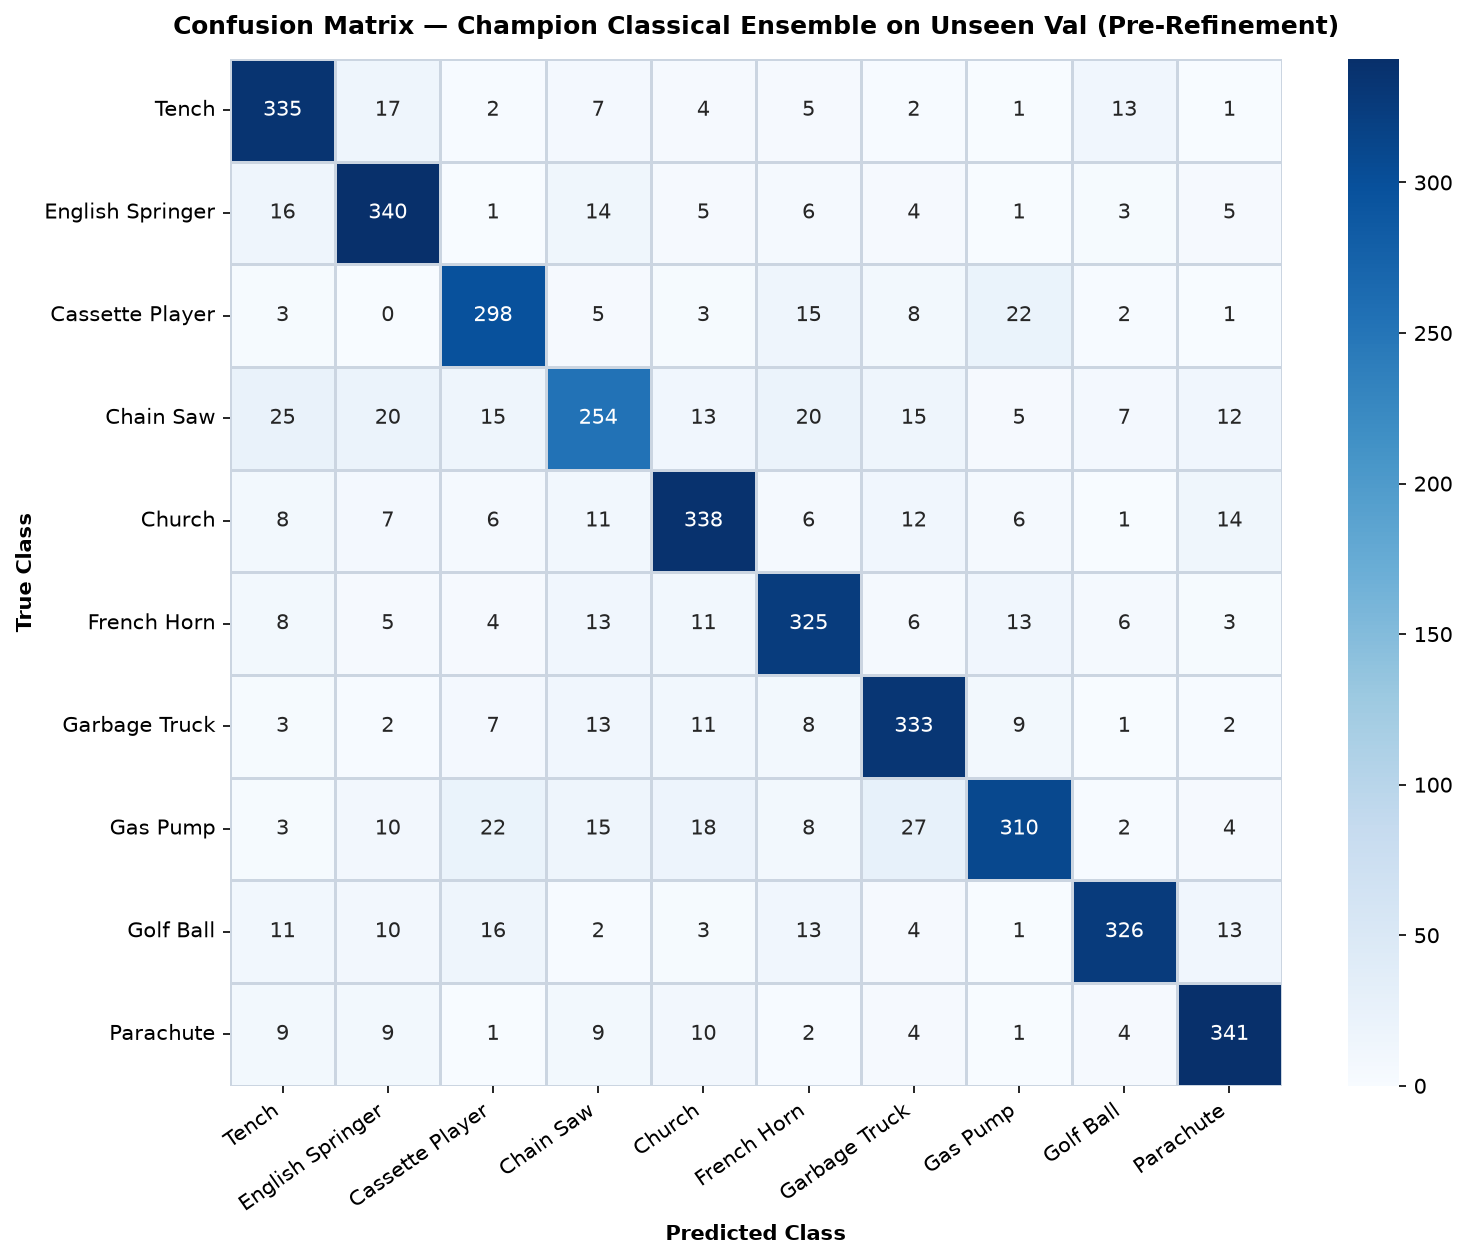

=== Top 5 Directed Off-Diagonal Misclassifications (True -> Predicted) ===
  1. Gas Pump -> Garbage Truck: 27 errors (reverse Garbage Truck -> Gas Pump: 9)
  2. Chain Saw -> Tench: 25 errors (reverse Tench -> Chain Saw: 7)
  3. Cassette Player -> Gas Pump: 22 errors (reverse Gas Pump -> Cassette Player: 22)
  4. Gas Pump -> Cassette Player: 22 errors (reverse Cassette Player -> Gas Pump: 22)
  5. Chain Saw -> English Springer: 20 errors (reverse English Springer -> Chain Saw: 14)

>>> LARGEST OFF-DIAGONAL CELL: True='Gas Pump' predicted as 'Garbage Truck' (27 errors; bidirectional total = 36)


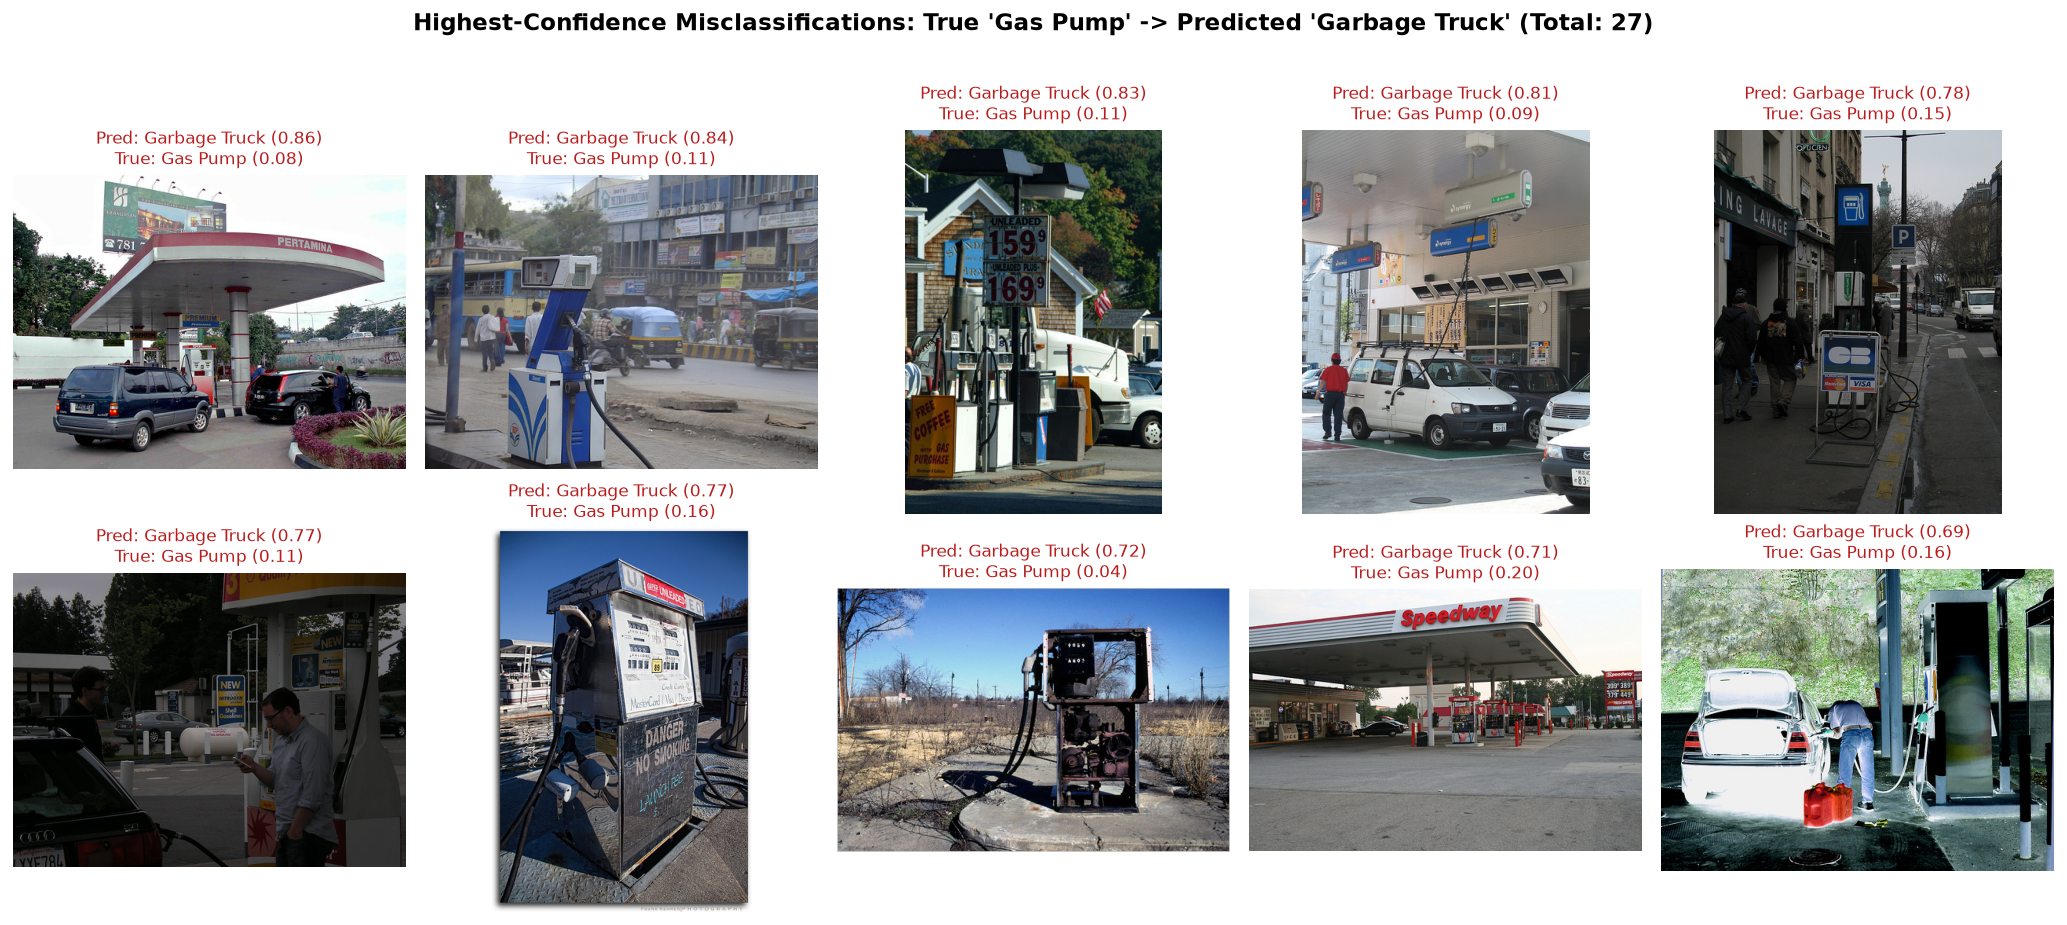

In [14]:
# 1. Compute and plot 10x10 Confusion Matrix
cm = confusion_matrix(y_val, val_ens_preds)

fig, ax = plt.subplots(figsize=(10.5, 8.5), dpi=150)
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=class_names, yticklabels=class_names,
    linewidths=0.5, linecolor="#CBD5E1", ax=ax
)
ax.set_title("Confusion Matrix — Champion Classical Ensemble on Unseen Val (Pre-Refinement)", fontweight="bold", pad=12)
ax.set_xlabel("Predicted Class", fontweight="bold")
ax.set_ylabel("True Class", fontweight="bold")
plt.xticks(rotation=35, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig("assets/confusion_matrix_pre.png", dpi=200, bbox_inches="tight")
plt.show()

# 2. Identify Top Off-Diagonal Errors (Directed & Symmetric)
cm_off = cm.copy()
np.fill_diagonal(cm_off, 0)

# Top 5 directed off-diagonal errors
flat_idx = np.argsort(cm_off.ravel())[::-1]
print("=== Top 5 Directed Off-Diagonal Misclassifications (True -> Predicted) ===")
directed_pairs = []
for k in range(5):
    r, c = np.unravel_index(flat_idx[k], cm_off.shape)
    cnt = int(cm_off[r, c])
    directed_pairs.append((r, c, cnt))
    print(f"  {k+1}. {IDX_TO_NAME[r]} -> {IDX_TO_NAME[c]}: {cnt} errors (reverse {IDX_TO_NAME[c]} -> {IDX_TO_NAME[r]}: {cm_off[c, r]})")

# Extract the single largest off-diagonal error
top_true_idx, top_pred_idx, top_err_cnt = directed_pairs[0]
top_true_name, top_pred_name = IDX_TO_NAME[top_true_idx], IDX_TO_NAME[top_pred_idx]
rev_err_cnt = int(cm_off[top_pred_idx, top_true_idx])
print(f"\n>>> LARGEST OFF-DIAGONAL CELL: True='{top_true_name}' predicted as '{top_pred_name}' ({top_err_cnt} errors; bidirectional total = {top_err_cnt + rev_err_cnt})")

# 3. Visualize up to 10 Misclassified Samples from the Top Off-Diagonal Cell (sorted by model confidence)
err_mask = (y_val == top_true_idx) & (val_ens_preds == top_pred_idx)
err_indices = np.where(err_mask)[0]
err_confs = val_ens_proba[err_indices, top_pred_idx]
sorted_err_idx = err_indices[np.argsort(err_confs)[::-1]]  # Highest confidence mistakes first

n_show = min(10, len(sorted_err_idx))
fig, axes = plt.subplots(2, 5, figsize=(16, 7), dpi=130)
axes = axes.ravel()

for i in range(10):
    if i < n_show:
        idx = sorted_err_idx[i]
        img = load_image_rgb(val_df.iloc[idx]["path"])
        p_pred = val_ens_proba[idx, top_pred_idx]
        p_true = val_ens_proba[idx, top_true_idx]
        axes[i].imshow(img)
        axes[i].set_title(
            f"Pred: {top_pred_name} ({p_pred:.2f})\nTrue: {top_true_name} ({p_true:.2f})",
            fontsize=9.5, color="#B91C1C"
        )
    axes[i].axis("off")

plt.suptitle(
    f"Highest-Confidence Misclassifications: True '{top_true_name}' -> Predicted '{top_pred_name}' (Total: {top_err_cnt})",
    fontsize=13, fontweight="bold", y=1.01
)
plt.tight_layout()
plt.savefig("assets/top_error_samples.png", dpi=180, bbox_inches="tight")
plt.show()

## 15. Targeted Error Mitigation — Part A: Spatial Pyramid & Geometric-Directional Features
Visual inspection of the top off-diagonal error (`Gas Pump -> Garbage Truck`, `27` errors) revealed three root causes:
1. **Shared Outdoor Vehicle/Road Context:** Parked cars, vans, asphalt, and canopies dominate standard global descriptors and orderless BoVW histograms.
2. **Loss of Native Aspect Ratio & Verticality:** Squashing images to `128×128` erases the tall vertical geometry of gas pumps versus the wide horizontal silhouette of garbage trucks.
3. **Foreground/Background Mixing:** Background clutter overwhelms the localized pump structure.

To address these causes directly without any data leakage, we engineer two targeted classical feature blocks:
- **Spatial Pyramid RootSIFT (`SPM-BoVW`, `1,280` dims — *Lazebnik et al., CVPR 2006*):** Quantizes RootSIFT keypoints (`K=256`, trained strictly on `train`) across `2×2` spatial quadrants plus a `Center 50%` foreground crop, followed by train-fitted Sublinear TF-IDF + $L_2$ normalization.
- **Geometric, Center-vs-Border & Directional Gabor (`GeomGabor`, `55` dims):** Captures native aspect ratio before resizing, vertical-vs-horizontal Sobel edge ratios (center vs. border), center-vs-border HSV/Lab contrast, and an 8-filter directional Gabor bank (`0°, 45°, 90°, 135°` at 2 scales).

In [15]:
REFINEMENT_CACHE_PATH = CACHE_DIR / "refinement_features.npz"
SPM_K = 256
SPM_MAX_KMEANS_SAMPLES = 250_000

# Precompute 8 Directional Gabor kernels (4 orientations x 2 wavelengths)
_GABOR_KERNELS = []
for lambd in (6.0, 12.0):
    sigma = 0.56 * lambd
    for theta in (0.0, np.pi / 4, np.pi / 2, 3 * np.pi / 4):
        k = cv2.getGaborKernel((15, 15), sigma, theta, lambd, gamma=0.5, psi=0, ktype=cv2.CV_32F)
        k /= (np.abs(k).sum() + 1e-7)
        _GABOR_KERNELS.append(k)


def extract_geom_gabor_for_path(path: str) -> np.ndarray:
    """Extracts 55-dim Native Aspect + Vertical/Horizontal Edge + Center-vs-Border + Directional Gabor features."""
    img_raw = load_image_rgb(path)
    orig_h, orig_w = img_raw.shape[:2]

    # 1. Native Aspect Ratio Geometry (3 dims — lost by 128x128 resize)
    aspect = orig_w / (orig_h + 1e-6)
    aspect_feats = np.array([aspect, np.log(aspect + 1e-6), float(orig_h > orig_w)], dtype=np.float32)

    img_rgb = resize_for_global(img_raw, GLOBAL_SIZE)
    img_gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY).astype(np.float32) / 255.0
    h, w = img_gray.shape
    c_sl = (slice(h // 4, 3 * h // 4), slice(w // 4, 3 * w // 4))  # Inner 50% foreground box

    border_mask = np.ones((h, w), dtype=bool)
    border_mask[c_sl] = False

    # 2. Vertical (|Gx|) vs. Horizontal (|Gy|) Sobel Ratios in Full / Center / Border (6 dims)
    gx = np.abs(cv2.Sobel(img_gray, cv2.CV_32F, 1, 0, ksize=3))
    gy = np.abs(cv2.Sobel(img_gray, cv2.CV_32F, 0, 1, ksize=3))
    gmag = np.hypot(gx, gy)

    v_ratio_full = gx.mean() / (gy.mean() + 1e-6)
    v_ratio_center = gx[c_sl].mean() / (gy[c_sl].mean() + 1e-6)
    v_ratio_border = gx[border_mask].mean() / (gy[border_mask].mean() + 1e-6)
    center_edge_ratio = gmag[c_sl].mean() / (gmag[border_mask].mean() + 1e-6)
    edge_feats = np.array([
        v_ratio_full, v_ratio_center, v_ratio_border,
        center_edge_ratio, gx[c_sl].mean(), gy[c_sl].mean()
    ], dtype=np.float32)

    # 3. Center-vs-Border Color Contrast in HSV & Lab (12 dims)
    cb_feats = []
    for space in (cv2.cvtColor(img_rgb, cv2.COLOR_RGB2HSV), cv2.cvtColor(img_rgb, cv2.COLOR_RGB2LAB)):
        space_f = space.astype(np.float32)
        for ch in range(3):
            c_vals = space_f[c_sl[0], c_sl[1], ch]
            b_vals = space_f[:, :, ch][border_mask]
            cb_feats.extend([c_vals.mean() - b_vals.mean(), c_vals.std() - b_vals.std()])
    cb_feats = np.array(cb_feats, dtype=np.float32)

    # 4. Directional Gabor Filter Bank: Full & Center mean/std (32 dims) + Vertical/Horizontal Ratios (2 dims)
    gabor_feats = []
    vh_ratios = []
    for scale_idx in range(2):
        resp_energies = []
        for orient_idx in range(4):
            kern = _GABOR_KERNELS[scale_idx * 4 + orient_idx]
            resp = np.abs(cv2.filter2D(img_gray, cv2.CV_32F, kern))
            resp_c = resp[c_sl]
            gabor_feats.extend([resp.mean(), resp.std(), resp_c.mean(), resp_c.std()])
            resp_energies.append(resp_c.mean())
        # orient 0 (vertical edges) vs orient 2 (horizontal edges)
        vh_ratios.append(resp_energies[0] / (resp_energies[2] + 1e-6))

    out = np.concatenate([
        aspect_feats, edge_feats, cb_feats,
        np.array(gabor_feats + vh_ratios, dtype=np.float32)
    ])
    return np.nan_to_num(out).astype(np.float32)


def extract_rootsift_with_coords(path: str):
    """Extracts RootSIFT descriptors (N, 128) and normalized coordinates (N, 2) in [0, 1]."""
    img_rgb = resize_for_local(load_image_rgb(path), max_side=LOCAL_MAX_SIDE)
    img_gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    h, w = img_gray.shape

    sift = cv2.SIFT_create(nfeatures=MAX_KEYPOINTS)
    kps, des = sift.detectAndCompute(img_gray, None)

    if des is None or len(des) == 0:
        return np.empty((0, 128), dtype=np.float32), np.empty((0, 2), dtype=np.float32)

    des = des.astype(np.float32)
    des /= (des.sum(axis=1, keepdims=True) + 1e-7)
    des = np.sqrt(des)

    coords = np.array([[kp.pt[0] / w, kp.pt[1] / h] for kp in kps], dtype=np.float32)
    return des, coords


def encode_spm_histograms(desc_coord_list, kmeans: MiniBatchKMeans, k: int) -> np.ndarray:
    """Encodes keypoints into 5 spatial regions (2x2 quadrants + center 50% crop) -> (N, 5*k)."""
    hists = np.zeros((len(desc_coord_list), 5 * k), dtype=np.float32)
    for i, (des, coords) in enumerate(desc_coord_list):
        if len(des) == 0:
            continue
        words = kmeans.predict(des)
        nx, ny = coords[:, 0], coords[:, 1]

        masks = [
            (nx < 0.5) & (ny < 0.5),                                  # Top-Left
            (nx >= 0.5) & (ny < 0.5),                                 # Top-Right
            (nx < 0.5) & (ny >= 0.5),                                 # Bottom-Left
            (nx >= 0.5) & (ny >= 0.5),                                # Bottom-Right
            (nx >= 0.25) & (nx <= 0.75) & (ny >= 0.25) & (ny <= 0.75) # Center 50% Foreground
        ]
        for r_idx, m in enumerate(masks):
            if np.any(m):
                hists[i, r_idx * k : (r_idx + 1) * k] = np.bincount(words[m], minlength=k)
    return hists


if USE_CACHE and REFINEMENT_CACHE_PATH.exists():
    print(f"Loading cached refinement features from {REFINEMENT_CACHE_PATH}...")
    ref_data = np.load(REFINEMENT_CACHE_PATH)
    X_tr_geom, X_va_geom = ref_data["tr_geom"], ref_data["va_geom"]
    X_tr_spm, X_va_spm = ref_data["tr_spm"], ref_data["va_spm"]
    t_tr_ref, t_va_ref = float(ref_data["t_tr"]), float(ref_data["t_va"])
else:
    # --- Train Phase ---
    t0_tr = time.perf_counter()
    X_tr_geom = np.vstack(Parallel(n_jobs=-1, prefer="processes")(
        delayed(extract_geom_gabor_for_path)(p) for p in tqdm(train_df["path"], desc="GeomGabor Train")
    ))
    tr_dc = Parallel(n_jobs=-1, prefer="processes")(
        delayed(extract_rootsift_with_coords)(p) for p in tqdm(train_df["path"], desc="SPM-RootSIFT Train")
    )
    all_tr_des = np.vstack([d for d, _ in tr_dc if len(d) > 0])
    rng = np.random.default_rng(SEED)
    if len(all_tr_des) > SPM_MAX_KMEANS_SAMPLES:
        s_idx = rng.choice(len(all_tr_des), size=SPM_MAX_KMEANS_SAMPLES, replace=False)
        km_in = all_tr_des[s_idx]
    else:
        km_in = all_tr_des

    print(f"Fitting SPM MiniBatchKMeans (K={SPM_K}) strictly on {len(km_in):,} train descriptors...")
    spm_kmeans = MiniBatchKMeans(n_clusters=SPM_K, batch_size=4096, random_state=SEED, n_init=3, max_iter=150)
    spm_kmeans.fit(km_in)
    del all_tr_des, km_in

    X_tr_spm_raw = encode_spm_histograms(tr_dc, spm_kmeans, SPM_K)
    del tr_dc
    spm_tfidf = TfidfTransformer(norm="l2", use_idf=True, smooth_idf=True, sublinear_tf=True)
    X_tr_spm = spm_tfidf.fit_transform(X_tr_spm_raw).toarray().astype(np.float32)
    t_tr_ref = time.perf_counter() - t0_tr

    # --- Val Phase (Transform Only — Zero Leakage) ---
    t0_va = time.perf_counter()
    X_va_geom = np.vstack(Parallel(n_jobs=-1, prefer="processes")(
        delayed(extract_geom_gabor_for_path)(p) for p in tqdm(val_df["path"], desc="GeomGabor Val")
    ))
    va_dc = Parallel(n_jobs=-1, prefer="processes")(
        delayed(extract_rootsift_with_coords)(p) for p in tqdm(val_df["path"], desc="SPM-RootSIFT Val")
    )
    X_va_spm_raw = encode_spm_histograms(va_dc, spm_kmeans, SPM_K)
    del va_dc
    X_va_spm = spm_tfidf.transform(X_va_spm_raw).toarray().astype(np.float32)
    t_va_ref = time.perf_counter() - t0_va

    np.savez_compressed(
        REFINEMENT_CACHE_PATH,
        tr_geom=X_tr_geom, va_geom=X_va_geom,
        tr_spm=X_tr_spm, va_spm=X_va_spm,
        t_tr=t_tr_ref, t_va=t_va_ref
    )
    print(f"Saved refinement features to {REFINEMENT_CACHE_PATH}")

print(f"\nRefinement Extraction Runtime -> Train: {t_tr_ref:.2f}s | Val: {t_va_ref:.2f}s")
print(f"Shapes -> GeomGabor: {X_tr_geom.shape} | SPM-BoVW: {X_tr_spm.shape}")

GeomGabor Train:   0%|          | 0/9469 [00:00<?, ?it/s]

SPM-RootSIFT Train:   0%|          | 0/9469 [00:00<?, ?it/s]

Fitting SPM MiniBatchKMeans (K=256) strictly on 250,000 train descriptors...


GeomGabor Val:   0%|          | 0/3925 [00:00<?, ?it/s]

SPM-RootSIFT Val:   0%|          | 0/3925 [00:00<?, ?it/s]

Saved refinement features to cache/refinement_features.npz

Refinement Extraction Runtime -> Train: 94.34s | Val: 39.41s
Shapes -> GeomGabor: (9469, 55) | SPM-BoVW: (9469, 1280)


## 16. Targeted Error Mitigation — Part B: Refined Ensemble + Pairwise Specialist & Pre/Post Comparison
We integrate our two targeted feature blocks (`SPM_BoVW` and `GeomGabor`) into the leakage-free fusion pipeline (`4,083` total dims) and add a **Dedicated Pairwise Specialist (`Gas Pump` vs. `Garbage Truck`)** trained strictly on training samples belonging to those two classes:
1. Run 5-Fold CV on `train` to obtain leakage-free out-of-fold probabilities for both the refined 10-class models and the binary `{Gas Pump, Garbage Truck}` specialist.
2. Tune the specialist probability reallocation weight $\alpha$ strictly on 5-Fold OOF: whenever the ensemble's top-2 predictions are `{Gas Pump, Garbage Truck}`, only their joint probability mass $M = p_{\text{gas}} + p_{\text{truck}}$ is redistributed—leaving the remaining 8 classes untouched.
3. Retrain the refined pipeline on full `train`, evaluate on unseen `val`, and report a complete **Pre-Refinement vs. Post-Refinement** comparison alongside a confusion-matrix difference plot.

Building leakage-free 5-Fold CV for 7-family pipeline & Pairwise Specialist (Gas Pump vs Garbage Truck)...


/home/kasrakra/Documents/AUT-Fall2026/Computer Vision/HWs/projects/project01/project01_venv/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/kasrakra/Documents/AUT-Fall2026/Computer Vision/HWs/projects/project01/project01_venv/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/kasrakra/Documents/AUT-Fall2026/Computer Vision/HWs/projects/project01/project01_venv/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=F

5-Fold CV for Refined SVM/LogReg + Pairwise Specialist completed in 491.5s
Refined 5-Fold CV -> SVM: 81.44% | LogReg: 80.57%

Tuning Pairwise Specialist weight (alpha) on Train 5-Fold OOF:
  alpha=0.00 -> OOF Acc: 81.76% | Gas Pump->Garbage Truck: 50 | Pair Total: 82
  alpha=0.20 -> OOF Acc: 81.76% | Gas Pump->Garbage Truck: 50 | Pair Total: 82
  alpha=0.35 -> OOF Acc: 81.77% | Gas Pump->Garbage Truck: 48 | Pair Total: 81
  alpha=0.50 -> OOF Acc: 81.77% | Gas Pump->Garbage Truck: 47 | Pair Total: 81
  alpha=0.65 -> OOF Acc: 81.77% | Gas Pump->Garbage Truck: 46 | Pair Total: 81
  alpha=0.80 -> OOF Acc: 81.75% | Gas Pump->Garbage Truck: 47 | Pair Total: 83
--> Selected alpha = 0.35 (strictly via Train 5-Fold CV)



/home/kasrakra/Documents/AUT-Fall2026/Computer Vision/HWs/projects/project01/project01_venv/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


,Stage,Val Accuracy,Macro F1,Gas Pump Recall,Garbage Truck Recall,Gas Pump->Garbage Truck Err,Bidirectional Pair Err,Fit Time (s),Val Inf (s)
0,Pre-Refinement (5 Families),0.815287,0.814408,0.739857,0.856041,27,36,243.6,50.6
1,Post-Refinement (+SPM +GeomGabor +Specialist),0.828025,0.827205,0.778043,0.863753,21,32,401.8,100.4



=== Post-Refinement Per-Class Classification Report (Unseen Val) ===
                  precision    recall  f1-score   support

           Tench     0.8232    0.8786    0.8500       387
English Springer     0.8277    0.8633    0.8451       395
 Cassette Player     0.8165    0.8599    0.8377       357
       Chain Saw     0.7544    0.6684    0.7088       386
          Church     0.8480    0.8460    0.8470       409
     French Horn     0.8025    0.8249    0.8135       394
   Garbage Truck     0.8136    0.8638    0.8379       389
        Gas Pump     0.8338    0.7780    0.8049       419
       Golf Ball     0.8904    0.8346    0.8616       399
       Parachute     0.8645    0.8667    0.8656       390

        accuracy                         0.8280      3925
       macro avg     0.8274    0.8284    0.8272      3925
    weighted avg     0.8279    0.8280    0.8272      3925



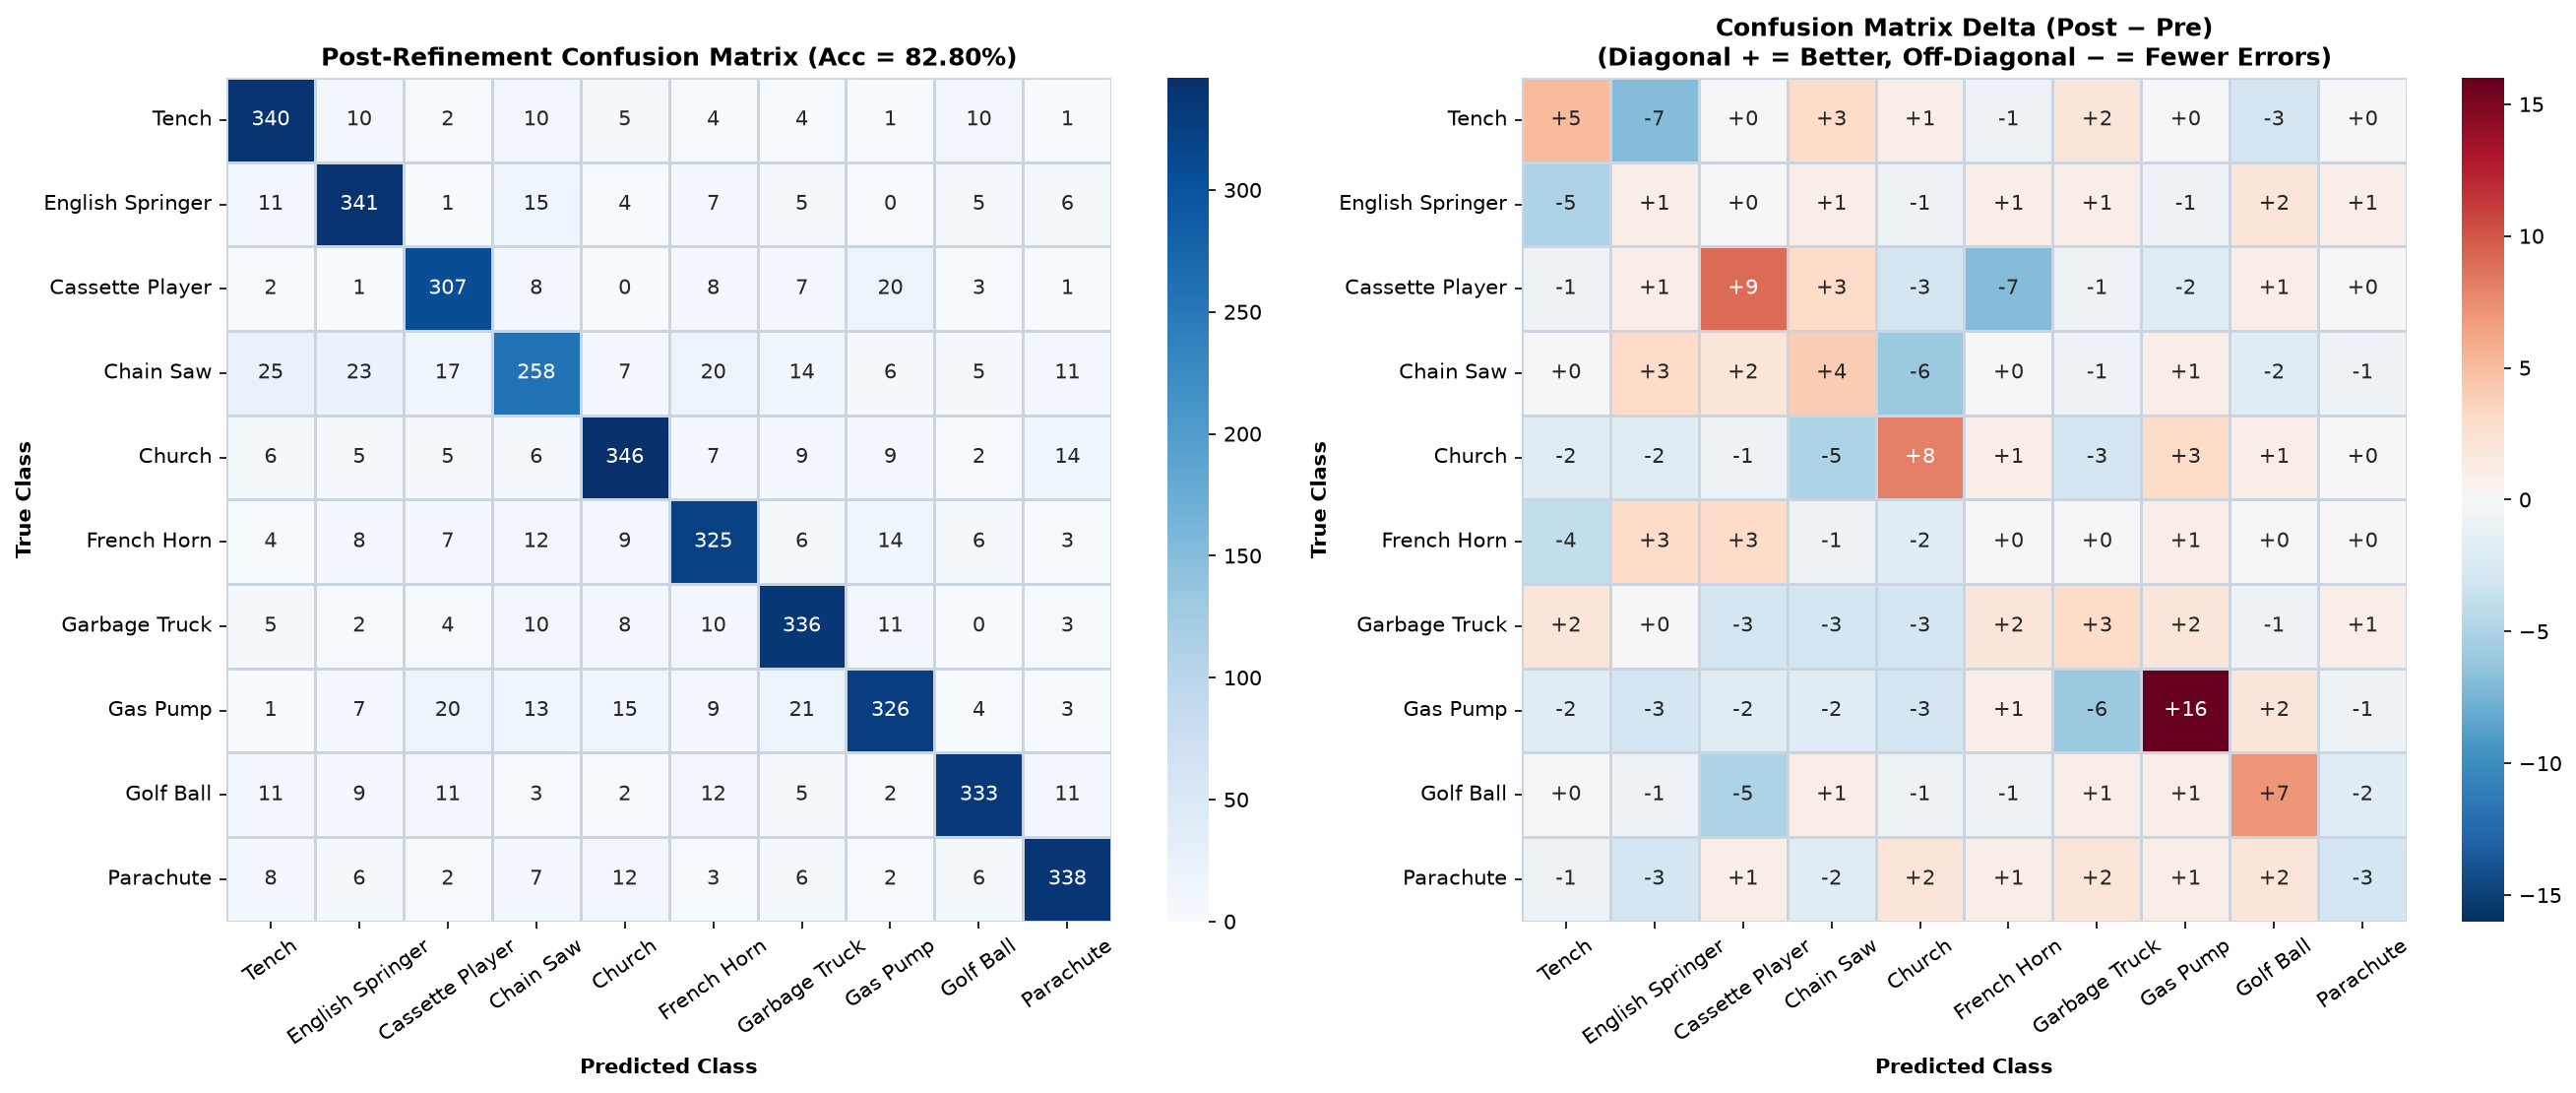

In [16]:
# 1. Assemble 7-Family Refined Feature Dictionaries
TRAIN_FEATURES_REF = {**TRAIN_FEATURES, "SPM_BoVW": X_tr_spm, "GeomGabor": X_tr_geom}
VAL_FEATURES_REF = {**VAL_FEATURES, "SPM_BoVW": X_va_spm, "GeomGabor": X_va_geom}
REF_FAMILIES = list(TRAIN_FEATURES_REF.keys())

REF_WEIGHTS = {
    **BEST_WEIGHTS,
    "SPM_BoVW": 1.05,
    "GeomGabor": 0.90,
}

# Precompute column slices for 7-family weighted fusion
REF_SLICES = {}
_c = 0
for fam in REF_FAMILIES:
    d = TRAIN_FEATURES_REF[fam].shape[1]
    REF_SLICES[fam] = slice(_c, _c + d)
    _c += d

def apply_ref_weights(X: np.ndarray, weights: dict) -> np.ndarray:
    X_w = X.copy()
    for fam, w in weights.items():
        if w != 1.0:
            X_w[:, REF_SLICES[fam]] *= np.float32(w)
    return X_w

# 2. Leakage-Free 5-Fold CV for Refined SVM, Refined LogReg & Pairwise Specialist
PAIR_A, PAIR_B = top_true_idx, top_pred_idx  # Gas Pump (7) & Garbage Truck (6)
print(f"Building leakage-free 5-Fold CV for 7-family pipeline & Pairwise Specialist ({IDX_TO_NAME[PAIR_A]} vs {IDX_TO_NAME[PAIR_B]})...")

def _run_ref_fold(f):
    tr_idx = np.where(folds != f)[0]
    va_idx = np.where(folds == f)[0]
    X_tr_f, X_va_f = fuse_blocks_fit_transform(TRAIN_FEATURES_REF, REF_FAMILIES, tr_idx, va_idx)
    X_tr_fw = apply_ref_weights(X_tr_f, REF_WEIGHTS)
    X_va_fw = apply_ref_weights(X_va_f, REF_WEIGHTS)

    # Refined 10-class SVM & LogReg
    svm_f = SVC(C=BEST_SVM_C, kernel="rbf", gamma="scale", decision_function_shape="ovr", random_state=SEED)
    svm_f.fit(X_tr_fw, y_train[tr_idx])
    svm_m = svm_f.decision_function(X_va_fw)

    lr_f = LogisticRegression(C=BEST_LR_C, solver="lbfgs", max_iter=600, random_state=SEED)
    lr_f.fit(X_tr_fw, y_train[tr_idx])
    lr_p = lr_f.predict_proba(X_va_fw)

    # Dedicated Pairwise Specialist strictly on {PAIR_A, PAIR_B} training samples in this fold
    pair_tr_mask = (y_train[tr_idx] == PAIR_A) | (y_train[tr_idx] == PAIR_B)
    Xp_tr = X_tr_fw[pair_tr_mask]
    yp_tr = (y_train[tr_idx][pair_tr_mask] == PAIR_A).astype(int)  # 1 = Gas Pump, 0 = Garbage Truck

    sp_svm = SVC(C=2.0, kernel="rbf", gamma="scale", probability=True, random_state=SEED)
    sp_svm.fit(Xp_tr, yp_tr)
    sp_lr = LogisticRegression(C=0.5, solver="lbfgs", max_iter=500, random_state=SEED)
    sp_lr.fit(Xp_tr, yp_tr)

    # Probability of PAIR_A (Gas Pump) given {PAIR_A, PAIR_B}
    sp_p_A = 0.65 * sp_svm.predict_proba(X_va_fw)[:, 1] + 0.35 * sp_lr.predict_proba(X_va_fw)[:, 1]
    return va_idx, svm_m.astype(np.float32), lr_p.astype(np.float32), sp_p_A.astype(np.float32)

t0_cv = time.perf_counter()
ref_fold_outs = Parallel(n_jobs=4, prefer="processes")(
    delayed(_run_ref_fold)(f) for f in range(N_FOLDS)
)
print(f"5-Fold CV for Refined SVM/LogReg + Pairwise Specialist completed in {time.perf_counter() - t0_cv:.1f}s")

oof_svm_ref_m = np.zeros((len(train_df), 10), dtype=np.float32)
oof_lr_ref_p = np.zeros((len(train_df), 10), dtype=np.float32)
oof_sp_p_A = np.zeros(len(train_df), dtype=np.float32)

for va_idx, svm_m, lr_p, sp_p in ref_fold_outs:
    oof_svm_ref_m[va_idx] = svm_m
    oof_lr_ref_p[va_idx] = lr_p
    oof_sp_p_A[va_idx] = sp_p

# Calibrate refined SVM OOF strictly out-of-fold
oof_svm_ref_p = np.zeros_like(oof_svm_ref_m)
for f in range(N_FOLDS):
    tr_idx, va_idx = np.where(folds != f)[0], np.where(folds == f)[0]
    cal = LogisticRegression(C=1.0, max_iter=500, random_state=SEED)
    cal.fit(oof_svm_ref_m[tr_idx], y_train[tr_idx])
    oof_svm_ref_p[va_idx] = cal.predict_proba(oof_svm_ref_m[va_idx])

print(f"Refined 5-Fold CV -> SVM: {accuracy_score(y_train, np.argmax(oof_svm_ref_m, axis=1))*100:.2f}% | "
      f"LogReg: {accuracy_score(y_train, np.argmax(oof_lr_ref_p, axis=1))*100:.2f}%")

# 3. Tune Specialist Blending Weight (alpha) strictly on Train OOF
def apply_pairwise_specialist(probs_10: np.ndarray, sp_prob_A: np.ndarray, alpha: float) -> np.ndarray:
    """Reallocates joint probability mass of {PAIR_A, PAIR_B} only when they are the top-2 predicted classes."""
    if alpha <= 0.0:
        return probs_10.copy()
    out = probs_10.copy()
    top2 = np.argsort(out, axis=1)[:, -2:]
    is_target_pair = (
        ((top2[:, 0] == PAIR_A) & (top2[:, 1] == PAIR_B)) |
        ((top2[:, 0] == PAIR_B) & (top2[:, 1] == PAIR_A))
    )
    idx = np.where(is_target_pair)[0]
    if len(idx) > 0:
        mass = out[idx, PAIR_A] + out[idx, PAIR_B] + 1e-12
        base_pA = out[idx, PAIR_A] / mass
        new_pA = (1.0 - alpha) * base_pA + alpha * sp_prob_A[idx]
        out[idx, PAIR_A] = mass * new_pA
        out[idx, PAIR_B] = mass * (1.0 - new_pA)
    return out

w_svm, w_lgb, w_lr = BEST_VOTE_WEIGHTS
oof_ref_blend = w_svm * oof_svm_ref_p + w_lgb * oof_lgbm_proba + w_lr * oof_lr_ref_p

best_alpha = 0.0
best_oof_score = -1.0
print("\nTuning Pairwise Specialist weight (alpha) on Train 5-Fold OOF:")
for a in [0.0, 0.20, 0.35, 0.50, 0.65, 0.80]:
    adj_p = apply_pairwise_specialist(oof_ref_blend, oof_sp_p_A, a)
    preds_a = np.argmax(adj_p, axis=1)
    acc_a = accuracy_score(y_train, preds_a)
    cm_a = confusion_matrix(y_train, preds_a)
    pair_err = cm_a[PAIR_A, PAIR_B] + cm_a[PAIR_B, PAIR_A]
    print(f"  alpha={a:.2f} -> OOF Acc: {acc_a*100:.2f}% | {IDX_TO_NAME[PAIR_A]}->{IDX_TO_NAME[PAIR_B]}: {cm_a[PAIR_A, PAIR_B]} | Pair Total: {pair_err}")
    if acc_a > best_oof_score:
        best_oof_score = acc_a
        best_alpha = a

print(f"--> Selected alpha = {best_alpha:.2f} (strictly via Train 5-Fold CV)\n")

# 4. Fit Final Refined Pipeline on FULL Train & Evaluate on Unseen Val
tr_ref_blocks, va_ref_blocks = [], []
for fam in REF_FAMILIES:
    sc = StandardScaler()
    tr_ref_blocks.append(normalize(sc.fit_transform(TRAIN_FEATURES_REF[fam]), norm="l2", axis=1))
    va_ref_blocks.append(normalize(sc.transform(VAL_FEATURES_REF[fam]), norm="l2", axis=1))

X_tr_ref_full = np.hstack(tr_ref_blocks).astype(np.float32)
X_va_ref_full = np.hstack(va_ref_blocks).astype(np.float32)
X_tr_ref_w = apply_ref_weights(X_tr_ref_full, REF_WEIGHTS)
X_va_ref_w = apply_ref_weights(X_va_ref_full, REF_WEIGHTS)

t0_rfit = time.perf_counter()
svm_ref_final = SVC(C=BEST_SVM_C, kernel="rbf", gamma="scale", decision_function_shape="ovr", random_state=SEED)
svm_ref_final.fit(X_tr_ref_w, y_train)
svm_ref_cal = LogisticRegression(C=1.0, max_iter=500, random_state=SEED)
svm_ref_cal.fit(oof_svm_ref_m, y_train)

lgbm_ref_final = LGBMClassifier(**LGBM_PARAMS)
lgbm_ref_final.fit(X_tr_ref_full, y_train)

lr_ref_final = LogisticRegression(C=BEST_LR_C, solver="lbfgs", max_iter=600, random_state=SEED)
lr_ref_final.fit(X_tr_ref_w, y_train)

# Full-train Pairwise Specialist
pair_full_mask = (y_train == PAIR_A) | (y_train == PAIR_B)
Xp_full = X_tr_ref_w[pair_full_mask]
yp_full = (y_train[pair_full_mask] == PAIR_A).astype(int)
sp_svm_final = SVC(C=2.0, kernel="rbf", gamma="scale", probability=True, random_state=SEED).fit(Xp_full, yp_full)
sp_lr_final = LogisticRegression(C=0.5, solver="lbfgs", max_iter=500, random_state=SEED).fit(Xp_full, yp_full)
t_ref_fit = time.perf_counter() - t0_rfit

# Inference on Unseen Val
t0_rinf = time.perf_counter()
va_svm_ref_p = svm_ref_cal.predict_proba(svm_ref_final.decision_function(X_va_ref_w))
va_lgbm_ref_p = lgbm_ref_final.predict_proba(X_va_ref_full)
va_lr_ref_p = lr_ref_final.predict_proba(X_va_ref_w)

val_ref_proba_raw = w_svm * va_svm_ref_p + w_lgb * va_lgbm_ref_p + w_lr * va_lr_ref_p
va_sp_pA = 0.65 * sp_svm_final.predict_proba(X_va_ref_w)[:, 1] + 0.35 * sp_lr_final.predict_proba(X_va_ref_w)[:, 1]
val_ref_proba_final = apply_pairwise_specialist(val_ref_proba_raw, va_sp_pA, best_alpha)
val_ref_preds = np.argmax(val_ref_proba_final, axis=1)
t_ref_inf = time.perf_counter() - t0_rinf

# 5. Pre- vs. Post-Refinement Comparison Table
cm_post = confusion_matrix(y_val, val_ref_preds)

def _metrics_row(label, preds, cm_mat, fit_s, inf_s):
    gas_rec = cm_mat[PAIR_A, PAIR_A] / cm_mat[PAIR_A].sum()
    trk_rec = cm_mat[PAIR_B, PAIR_B] / cm_mat[PAIR_B].sum()
    return {
        "Stage": label,
        "Val Accuracy": accuracy_score(y_val, preds),
        "Macro F1": f1_score(y_val, preds, average="macro"),
        f"{IDX_TO_NAME[PAIR_A]} Recall": gas_rec,
        f"{IDX_TO_NAME[PAIR_B]} Recall": trk_rec,
        f"{IDX_TO_NAME[PAIR_A]}->{IDX_TO_NAME[PAIR_B]} Err": int(cm_mat[PAIR_A, PAIR_B]),
        "Bidirectional Pair Err": int(cm_mat[PAIR_A, PAIR_B] + cm_mat[PAIR_B, PAIR_A]),
        "Fit Time (s)": round(fit_s, 1),
        "Val Inf (s)": round(inf_s, 1),
    }

comp_df = pd.DataFrame([
    _metrics_row("Pre-Refinement (5 Families)", val_ens_preds, cm, t_total_fit, t_total_inf),
    _metrics_row("Post-Refinement (+SPM +GeomGabor +Specialist)", val_ref_preds, cm_post, t_ref_fit, t_ref_inf),
])
display(comp_df)

print("\n=== Post-Refinement Per-Class Classification Report (Unseen Val) ===")
print(classification_report(y_val, val_ref_preds, target_names=class_names, digits=4))

# 6. Side-by-Side Post-Refinement Confusion Matrix & Change Heatmap (Post - Pre)
fig, axes = plt.subplots(1, 2, figsize=(18, 7.5), dpi=150)

sns.heatmap(
    cm_post, annot=True, fmt="d", cmap="Blues",
    xticklabels=class_names, yticklabels=class_names,
    linewidths=0.5, linecolor="#CBD5E1", ax=axes[0]
)
axes[0].set_title(f"Post-Refinement Confusion Matrix (Acc = {accuracy_score(y_val, val_ref_preds)*100:.2f}%)", fontweight="bold")
axes[0].set_xlabel("Predicted Class", fontweight="bold")
axes[0].set_ylabel("True Class", fontweight="bold")
axes[0].tick_params(axis="x", rotation=35)

cm_diff = cm_post - cm
vmax_d = max(5, int(np.abs(cm_diff).max()))
sns.heatmap(
    cm_diff, annot=True, fmt="+d", cmap="RdBu_r", center=0, vmin=-vmax_d, vmax=vmax_d,
    xticklabels=class_names, yticklabels=class_names,
    linewidths=0.5, linecolor="#CBD5E1", ax=axes[1]
)
axes[1].set_title("Confusion Matrix Delta (Post − Pre)\n(Diagonal + = Better, Off-Diagonal − = Fewer Errors)", fontweight="bold")
axes[1].set_xlabel("Predicted Class", fontweight="bold")
axes[1].set_ylabel("True Class", fontweight="bold")
axes[1].tick_params(axis="x", rotation=35)

plt.tight_layout()
plt.savefig("assets/refinement_comparison.png", dpi=200, bbox_inches="tight")
plt.show()